# Ejercicio 6: Aprendizaje basado en redes y algoritmos clásicos

**Tópicos Selectos en Aprendizaje Maquinal — TP N°1: Algoritmos para Reconocimiento de Patrones**

En este notebook se resuelve el Ejercicio 6 de la guía: se genera un problema de clasificación bidimensional con dos clases gaussianas que se solapan, se implementan **cuatro algoritmos clásicos** desde cero (perceptrón simple, $k$-medias, red de funciones de base radial y $k$ vecinos más cercanos) y se comparan entre sí y contra el clasificador óptimo de Bayes.

| Inciso | Consigna | Idea central |
|:--|:--|:--|
| **1** | Generar datos 2D en dos clases gaussianas correlacionadas, con cierto solapamiento | Como se conoce la fdp real, se puede calcular el error de Bayes (el mejor posible) |
| **2** | Perceptrón simple | Clasificador lineal; no converge si las clases se solapan |
| **3** | $k$-medias (batch) | Aprendizaje **no supervisado**: agrupa sin usar las etiquetas |
| **4** | Red neuronal de funciones de base radial (RBF) | Capa oculta local + salida lineal; entrenamiento híbrido |
| **5** | $k$ vecinos más cercanos | Método **no paramétrico** basado en memoria |
| **6** | Comparar y comentar los resultados | Sesgo/varianza, linealidad, costo, supervisión |

**Contenido**

1. [Datos](#1.-Datos)
2. [Perceptrón simple](#2.-Perceptrón-simple)
3. [k-medias (batch)](#3.-k-medias-(batch))
4. [Red de funciones de base radial (RBF)](#4.-Red-de-funciones-de-base-radial-(RBF))
5. [k vecinos más cercanos](#5.-k-vecinos-más-cercanos)
6. [Comparación de los métodos](#6.-Comparación-de-los-métodos)
7. [Conclusiones](#7.-Conclusiones)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(42)

---
## 1. Datos

> *Genere un conjunto de datos aleatorios bidimensionales separados en dos clases gaussianas correlacionadas con cierto grado de solapamiento.*

### 1.1 Diseño del problema

Se generan dos clases $\mathcal{N}(\boldsymbol{\mu}_k,\boldsymbol{\Sigma}_k)$ con **igual probabilidad a priori**. Se eligen con distinta covarianza (y ambas **correlacionadas**) para que el problema tenga una frontera óptima **no lineal**, y así los métodos lineales y no lineales se comporten de manera diferente:

| Clase | Etiqueta | Media $\boldsymbol{\mu}$ | Covarianza $\boldsymbol{\Sigma}$ | Forma |
|:--|:--:|:--:|:--:|:--|
| A | $-1$ | $(0,\,0)$ | $\begin{pmatrix}0.6&0.4\\0.4&0.6\end{pmatrix}$ | compacta, correlación positiva ($\rho\approx0.67$) |
| B | $+1$ | $(1.5,\,1.0)$ | $\begin{pmatrix}2.0&-1.0\\-1.0&1.5\end{pmatrix}$ | más dispersa, correlación negativa ($\rho\approx-0.58$) |

Las etiquetas se codifican como $\pm1$ por comodidad en los algoritmos siguientes.

**Error de Bayes como referencia.** Como se conocen las fdp reales, se dispone del **clasificador óptimo de Bayes** (ejercicio 2): asigna $\mathbf{x}$ a la clase de mayor $p(\mathbf{x}|\omega_k)P(\omega_k)$. Con covarianzas distintas, su frontera es una **cuádrica**. Su error es el mínimo que puede lograr *cualquier* clasificador con estas distribuciones, y sirve de techo para evaluar a los demás métodos. También se estima el error del **mejor clasificador lineal**, que es la cota que no puede superar (en promedio) un perceptrón.

**Protocolo de evaluación.** Se genera un conjunto de **entrenamiento** (150 muestras por clase) y uno de **prueba** (5000 por clase, para que la estimación del desempeño tenga poco ruido) independiente. Todo el ajuste de parámetros e hiperparámetros se hace *solo* con el entrenamiento; el conjunto de prueba se usa únicamente para informar el desempeño final.

In [2]:
MU = [np.array([0.0, 0.0]), np.array([1.5, 1.0])]
SIGMA = [np.array([[0.6, 0.4], [0.4, 0.6]]), np.array([[2.0, -1.0], [-1.0, 1.5]])]
ETIQ = [-1, +1]                         # etiqueta de cada clase (A, B)
COLOR = {-1: "tab:blue", +1: "tab:red"}
NOMBRE = {-1: "Clase A (−1)", +1: "Clase B (+1)"}


def generar_datos(n_por_clase, rng):
    '''Devuelve (X, y) con n_por_clase muestras de cada clase, mezcladas.'''
    X = np.vstack([rng.multivariate_normal(MU[k], SIGMA[k], n_por_clase) for k in (0, 1)])
    y = np.repeat(ETIQ, n_por_clase)
    p = rng.permutation(len(y))
    return X[p], y[p]


def exactitud(y, y_pred):
    return np.mean(y == y_pred)


# ---- Clasificador de Bayes (conoce la fdp real) ----
_pdf = [multivariate_normal(MU[k], SIGMA[k]) for k in (0, 1)]


def bayes_predecir(X):
    '''Prioridades iguales: la clase de mayor verosimilitud.'''
    return np.where(_pdf[0].logpdf(X) >= _pdf[1].logpdf(X), -1, +1)


X_tr, y_tr = generar_datos(150, rng)
X_te, y_te = generar_datos(5000, rng)
print(f"Entrenamiento: {X_tr.shape}  | Prueba: {X_te.shape}")
print(f"Acierto del clasificador de Bayes -> entrenamiento: {exactitud(y_tr, bayes_predecir(X_tr)) * 100:.2f}%"
      f" | prueba: {exactitud(y_te, bayes_predecir(X_te)) * 100:.2f}%")

Entrenamiento: (300, 2)  | Prueba: (10000, 2)
Acierto del clasificador de Bayes -> entrenamiento: 90.00% | prueba: 88.86%


In [3]:
# ---- Referencias teóricas por Monte Carlo (muestra grande) ----
rng_ref = np.random.default_rng(0)
X_mc, y_mc = generar_datos(200_000, rng_ref)
acc_bayes_mc = exactitud(y_mc, bayes_predecir(X_mc))


def mejor_lineal_mc(X, y, n_ang=360, n_umbral=400):
    '''Acierto del mejor clasificador lineal sign(w.x - t), buscando en dirección w (ángulo) y umbral t.'''
    mejor = 0
    for th in np.linspace(0, 2 * np.pi, n_ang, endpoint=False):
        s = X @ np.array([np.cos(th), np.sin(th)])
        ts = np.quantile(s, np.linspace(0.02, 0.98, n_umbral))
        s_orden = np.sort(s[y == -1]), np.sort(s[y == +1])
        # acierto = P(clase A, s <= t) + P(clase B, s > t), con priors 1/2
        acc = 0.5 * (np.searchsorted(s_orden[0], ts, side="right") / len(s_orden[0])
                     + 1 - np.searchsorted(s_orden[1], ts, side="right") / len(s_orden[1]))
        mejor = max(mejor, acc.max())
    return mejor


acc_lineal_mc = mejor_lineal_mc(X_mc, y_mc)
print(f"Acierto óptimo (Bayes), Monte Carlo 400 000 muestras : {acc_bayes_mc * 100:.2f}%   (error de Bayes = {(1 - acc_bayes_mc) * 100:.2f}%)")
print(f"Acierto del mejor clasificador lineal (estimado)      : {acc_lineal_mc * 100:.2f}%   (error = {(1 - acc_lineal_mc) * 100:.2f}%)")

Acierto óptimo (Bayes), Monte Carlo 400 000 muestras : 88.52%   (error de Bayes = 11.48%)
Acierto del mejor clasificador lineal (estimado)      : 82.94%   (error = 17.06%)


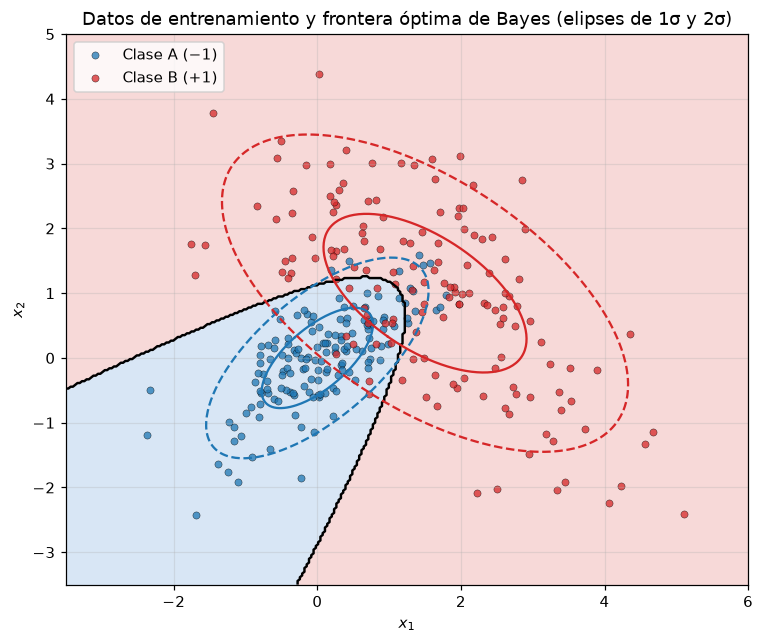

In [4]:
def elipse(mu, Sigma, k, n=200):
    lam, V = np.linalg.eigh(Sigma)
    t = np.linspace(0, 2 * np.pi, n)
    return (mu[:, None] + k * V @ (np.sqrt(lam)[:, None] * np.vstack([np.cos(t), np.sin(t)]))).T


def graficar_datos(ax, X, y, s=22, alpha=0.75):
    for c in (-1, +1):
        ax.scatter(*X[y == c].T, s=s, alpha=alpha, color=COLOR[c], edgecolor="k", lw=0.3, label=NOMBRE[c])


def graficar_regiones(ax, predecir, xlim, ylim, n=300, borde=True):
    '''Pinta las regiones de decisión de un clasificador que devuelve ±1.'''
    xx, yy = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    Z = predecir(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-1.5, 0, 1.5], colors=["#cfe0f3", "#f6d0cf"], alpha=0.8)
    if borde:
        ax.contour(xx, yy, Z, levels=[0], colors="k", linewidths=1.6)


XLIM, YLIM = (-3.5, 6.0), (-3.5, 5.0)

fig, ax = plt.subplots(figsize=(8, 6.5))
graficar_regiones(ax, bayes_predecir, XLIM, YLIM)
graficar_datos(ax, X_tr, y_tr)
for k in (0, 1):
    for m, ls in zip([1, 2], ["-", "--"]):
        e = elipse(MU[k], SIGMA[k], m)
        ax.plot(e[:, 0], e[:, 1], color=COLOR[ETIQ[k]], ls=ls, lw=1.5)
ax.set_xlim(XLIM); ax.set_ylim(YLIM)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.set_title("Datos de entrenamiento y frontera óptima de Bayes (elipses de 1σ y 2σ)")
ax.legend(loc="upper left")
plt.show()

**Observaciones.**

- La clase A es compacta y está rodeada, sobre todo hacia arriba y hacia la derecha, por la clase B, que es más dispersa y tiene la correlación de signo opuesto. Como las covarianzas son distintas, la frontera óptima de Bayes es **curva** (una cuádrica): una región cerrada alrededor de la clase A que se abre hacia la parte inferior izquierda.
- El **error de Bayes** es de $\approx11.5\,\%$ (acierto $88.5\,\%$): es el solapamiento propio del problema, que ningún método puede reducir.
- El **mejor clasificador lineal** posible llega solo a un acierto de $\approx82.9\,\%$ (error de $17.1\,\%$), **unos 5.6 puntos peor** que el óptimo. Esa brecha es la que deberían poder cerrar los métodos no lineales (RBF, $k$-NN) y la que ningún método lineal (perceptrón, $k$-medias con $K=2$) puede cerrar.
- Sobre las muestras concretas, el clasificador de Bayes acierta el $90.0\,\%$ de los 300 datos de entrenamiento y el $88.9\,\%$ del conjunto de prueba, consistente con el $88.5\,\%$ teórico (la diferencia en el entrenamiento es variabilidad del muestreo).

---
## 2. Perceptrón simple

> *Implemente el algoritmo de entrenamiento de un perceptrón simple y pruébelo con los datos anteriores, grafique los resultados obtenidos.*

### 2.1 Marco teórico

El **perceptrón simple** (Rosenblatt, 1958) es una neurona con función de activación escalón:

$$
\hat y(\mathbf{x})=\mathrm{sgn}\big(\mathbf{w}^\top\mathbf{x}+b\big)=\mathrm{sgn}\big(\tilde{\mathbf{w}}^\top\tilde{\mathbf{x}}\big),\qquad \tilde{\mathbf{x}}=(\mathbf{x},1),\ \tilde{\mathbf{w}}=(\mathbf{w},b).
$$

Su frontera de decisión $\mathbf{w}^\top\mathbf{x}+b=0$ es un **hiperplano** (una recta en 2D): solo puede representar clasificadores lineales.

**Regla de aprendizaje.** Se recorren los patrones $(\mathbf{x}_n,t_n)$ con $t_n\in\{-1,+1\}$ y, cada vez que uno se clasifica mal, se corrige el vector de pesos hacia él:

$$
\text{si } \hat y(\mathbf{x}_n)\neq t_n:\qquad \tilde{\mathbf{w}}\leftarrow\tilde{\mathbf{w}}+\eta\,t_n\,\tilde{\mathbf{x}}_n .
$$

Los patrones bien clasificados no producen cambios. Es el descenso por gradiente estocástico del **criterio del perceptrón** $E(\tilde{\mathbf{w}})=-\sum_{n\in\mathcal{M}}t_n\,\tilde{\mathbf{w}}^\top\tilde{\mathbf{x}}_n$, donde $\mathcal{M}$ es el conjunto de patrones mal clasificados. Una **época** es una pasada completa por los datos. Con $\tilde{\mathbf{w}}$ inicializado en cero, la tasa de aprendizaje $\eta$ solo escala a $\tilde{\mathbf{w}}$ y **no cambia las predicciones**, así que se toma $\eta=1$.

**Teorema de convergencia (Novikoff).** Si las clases son **linealmente separables**, el algoritmo converge en un número finito de correcciones (acotado por $(R/\gamma)^2$, con $R$ el radio de los datos y $\gamma$ el margen) a una solución que clasifica bien todo el entrenamiento.

**Cuando las clases se solapan** (como en este ejercicio) **no hay ningún hiperplano que las separe**, y el algoritmo **no converge**: sigue corrigiendo indefinidamente y los pesos oscilan. El resultado final depende del *último* patrón visitado y puede ser bastante peor que la mejor solución lineal. Una variante sencilla es el **algoritmo de bolsillo** (*pocket*): se entrena igual, pero se **guarda** el vector de pesos que menor error de entrenamiento haya logrado hasta el momento y se devuelve ese.

### 2.2 Implementación

In [5]:
class Perceptron:
    '''Perceptrón simple (regla de Rosenblatt, entrenamiento por patrón). Etiquetas en {-1, +1}.'''

    def __init__(self, eta=1.0, epocas=200, pocket=False, seed=0):
        self.eta, self.epocas, self.pocket, self.seed = eta, epocas, pocket, seed

    def decision(self, X):
        return X @ self.w_[:-1] + self.w_[-1]

    def predecir(self, X):
        return np.where(self.decision(X) >= 0, 1, -1)

    def fit(self, X, y):
        r = np.random.default_rng(self.seed)
        Xa = np.c_[X, np.ones(len(X))]                       # entrada aumentada (x, 1)
        w = np.zeros(Xa.shape[1])
        err = lambda w_: int(np.sum(np.where(Xa @ w_ >= 0, 1, -1) != y))

        mejor_w, mejor_err = w.copy(), err(w)                # "bolsillo"
        self.correcciones_, self.error_epoca_, self.w_epoca_ = [], [], []

        for ep in range(self.epocas):
            n_corr = 0
            for i in r.permutation(len(y)):                  # orden aleatorio en cada época
                if (1 if Xa[i] @ w >= 0 else -1) != y[i]:
                    w = w + self.eta * y[i] * Xa[i]          # regla de aprendizaje
                    n_corr += 1
                    if self.pocket:
                        e = err(w)
                        if e < mejor_err:
                            mejor_w, mejor_err = w.copy(), e
            self.correcciones_.append(n_corr)                # correcciones hechas durante la época
            self.error_epoca_.append(err(w))                 # errores de entrenamiento al final de la época
            self.w_epoca_.append(w.copy())
            if n_corr == 0:                                  # una época sin correcciones: convergió
                break
        self.convergio_ = self.correcciones_[-1] == 0
        self.w_ = mejor_w if self.pocket else w
        return self

### 2.3 Caso de referencia: datos linealmente separables

Antes de aplicarlo al problema con solapamiento, se verifica el teorema de convergencia con dos nubes **bien separadas**: el perceptrón debe terminar con error de entrenamiento nulo.

In [6]:
r_sep = np.random.default_rng(1)
X_sep = np.vstack([r_sep.normal([-2, -2], 0.7, (100, 2)), r_sep.normal([2, 2], 0.7, (100, 2))])
y_sep = np.repeat([-1, 1], 100)

p_sep = Perceptron(epocas=100).fit(X_sep, y_sep)
print(f"Datos separables: convergió = {p_sep.convergio_} en {len(p_sep.correcciones_)} épocas, "
      f"{sum(p_sep.correcciones_)} correcciones en total, error de entrenamiento final = {p_sep.error_epoca_[-1]}")
print("Correcciones por época:", p_sep.correcciones_)

Datos separables: convergió = True en 2 épocas, 1 correcciones en total, error de entrenamiento final = 0
Correcciones por época: [1, 0]


### 2.4 Aplicación a los datos con solapamiento

Se entrena el perceptrón durante 200 épocas, en su versión básica y en su versión *pocket*. Se grafican las rectas obtenidas, el número de errores y de correcciones por época, y el resultado sobre el conjunto de prueba.

In [7]:
perc = Perceptron(epocas=200, pocket=False, seed=0).fit(X_tr, y_tr)
perc_pk = Perceptron(epocas=200, pocket=True, seed=0).fit(X_tr, y_tr)

for nombre, m in [("Perceptrón (pesos finales)", perc), ("Perceptrón con bolsillo", perc_pk)]:
    print(f"{nombre:<28} | acierto entrenamiento: {exactitud(y_tr, m.predecir(X_tr)) * 100:5.2f}% "
          f"| prueba: {exactitud(y_te, m.predecir(X_te)) * 100:5.2f}%")
print(f"\nConvergió: {perc.convergio_}  | correcciones en las últimas 5 épocas: {perc.correcciones_[-5:]}")
print(f"Referencia: mejor clasificador lineal posible ≈ {acc_lineal_mc * 100:.2f}%  | Bayes ≈ {acc_bayes_mc * 100:.2f}%")

Perceptrón (pesos finales)   | acierto entrenamiento: 73.67% | prueba: 70.73%
Perceptrón con bolsillo      | acierto entrenamiento: 85.00% | prueba: 83.56%

Convergió: False  | correcciones en las últimas 5 épocas: [71, 68, 68, 61, 79]
Referencia: mejor clasificador lineal posible ≈ 82.94%  | Bayes ≈ 88.52%


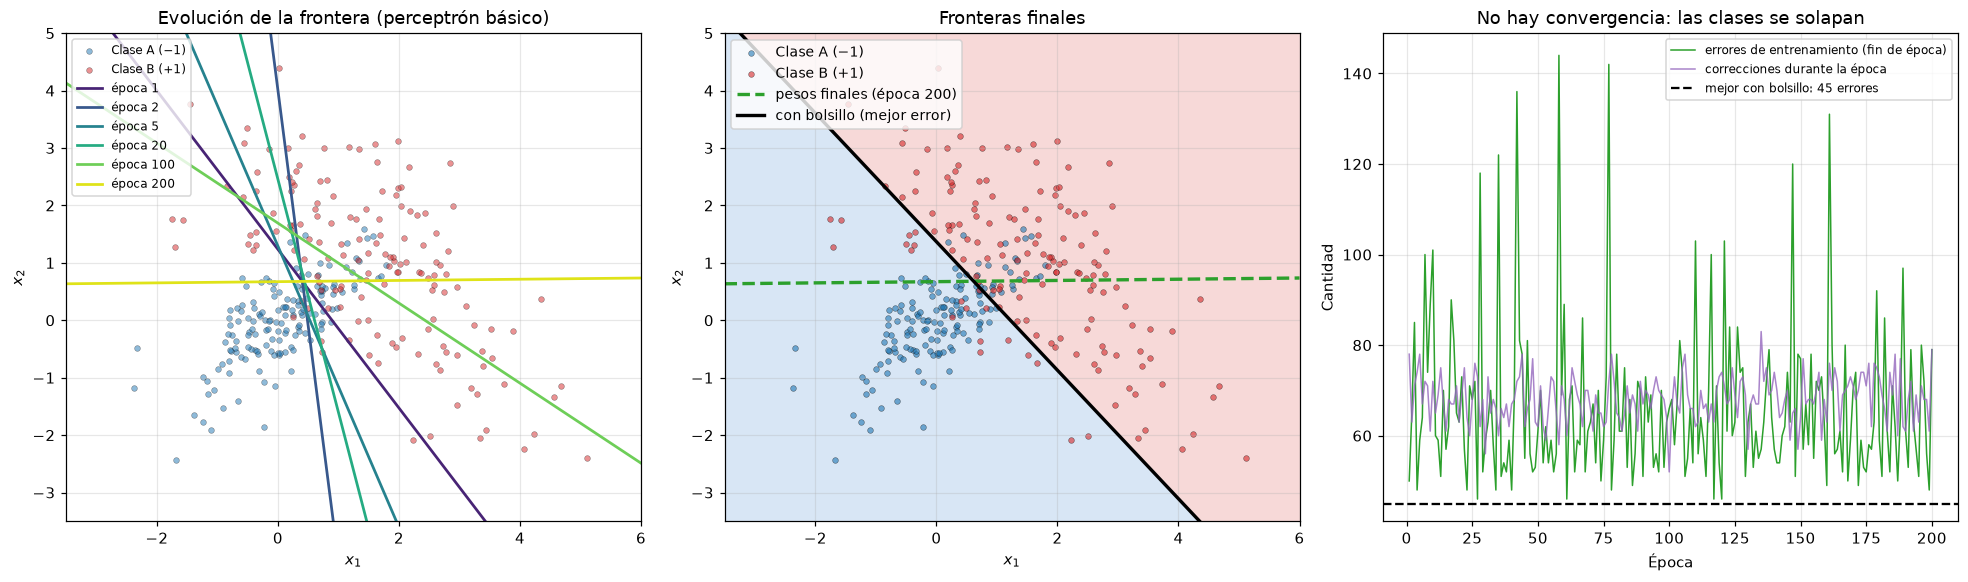

In [8]:
def graficar_recta(ax, w, xlim, **kw):
    '''Dibuja la recta w[0] x1 + w[1] x2 + w[2] = 0.'''
    x1 = np.array(xlim)
    if abs(w[1]) > 1e-12:
        ax.plot(x1, -(w[0] * x1 + w[2]) / w[1], **kw)


fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))

# (a) Evolución de la frontera durante el entrenamiento
ax = axes[0]
graficar_datos(ax, X_tr, y_tr, s=14, alpha=0.5)
epocas_mostrar = [e for e in [1, 2, 5, 20, 100, 200] if e <= len(perc.w_epoca_)]
cmap = plt.cm.viridis(np.linspace(0.1, 0.95, len(epocas_mostrar)))
for ep, c in zip(epocas_mostrar, cmap):
    graficar_recta(ax, perc.w_epoca_[ep - 1], XLIM, color=c, lw=1.8, label=f"época {ep}")
ax.set_xlim(XLIM); ax.set_ylim(YLIM)
ax.set_title("Evolución de la frontera (perceptrón básico)")
ax.legend(fontsize=8, loc="upper left")

# (b) Regiones finales: básico vs. pocket
ax = axes[1]
graficar_regiones(ax, perc_pk.predecir, XLIM, YLIM, borde=False)
graficar_datos(ax, X_tr, y_tr, s=14, alpha=0.6)
graficar_recta(ax, perc.w_, XLIM, color="tab:green", lw=2.2, ls="--", label="pesos finales (época 200)")
graficar_recta(ax, perc_pk.w_, XLIM, color="k", lw=2.2, label="con bolsillo (mejor error)")
ax.set_xlim(XLIM); ax.set_ylim(YLIM)
ax.set_title("Fronteras finales")
ax.legend(fontsize=9, loc="upper left")

# (c) Errores por época
ax = axes[2]
ax.plot(np.arange(1, len(perc.error_epoca_) + 1), perc.error_epoca_, color="tab:green", lw=1, label="errores de entrenamiento (fin de época)")
ax.plot(np.arange(1, len(perc.correcciones_) + 1), perc.correcciones_, color="tab:purple", lw=1, alpha=0.8, label="correcciones durante la época")
e_min = int(np.sum(perc_pk.predecir(X_tr) != y_tr))
ax.axhline(e_min, color="k", ls="--", label=f"mejor con bolsillo: {e_min} errores")
ax.set_xlabel("Época"); ax.set_ylabel("Cantidad")
ax.set_title("No hay convergencia: las clases se solapan")
ax.legend(fontsize=8)

for a in axes[:2]:
    a.set_xlabel("$x_1$"); a.set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

**Observaciones.**

- **Datos separables.** El perceptrón converge en 2 épocas (1 sola corrección) con error de entrenamiento nulo, como asegura el teorema de convergencia.
- **Datos con solapamiento: no converge.** En todas las épocas siguen ocurriendo entre unas 50 y 80 correcciones por pasada (sobre 300 patrones), y el número de errores al final de cada época oscila violentamente, entre unos 45 y 145. Las rectas de las distintas épocas saltan de casi verticales a casi horizontales. La solución que queda al terminar las 200 épocas depende del último patrón visitado: una recta casi horizontal con solo $73.7\,\%$ de acierto en entrenamiento y $70.7\,\%$ en prueba, claramente peor que la de otras épocas.
- **El bolsillo lo resuelve en gran parte.** Conservando los pesos de menor error de entrenamiento (45 errores sobre 300, es decir $85.0\,\%$) se obtiene una recta razonable, con $83.6\,\%$ de acierto en prueba, que coincide (dentro de la variabilidad del muestreo, $\pm0.4$) con el **mejor clasificador lineal posible** ($82.9\,\%$): es decir, el bolsillo encuentra casi la mejor recta que existe.
- **Variabilidad entre conjuntos de datos.** En las 30 réplicas de la sección 6 el perceptrón con los pesos finales acierta $76.8\pm5.2\,\%$ (con casos extremos de $55\,\%$), mientras que con bolsillo $82.2\pm0.9\,\%$ (mejora de $5.4\pm0.9$ puntos, en 28 de 30 réplicas).
- **Límite estructural.** Aun en su mejor versión, el perceptrón es un clasificador lineal y no puede pasar del $\approx83\,\%$, mientras que el óptimo es del $88.5\,\%$: el modelo no tiene la forma adecuada para esta frontera curva.

---
## 3. k-medias (batch)

> *Implemente el algoritmo de aprendizaje no supervisado $k$-medias (batch) y pruébelo con los datos anteriores, grafique los resultados obtenidos.*

### 3.1 Marco teórico

$k$-medias es un algoritmo de **agrupamiento no supervisado**: dado un conjunto de datos **sin etiquetas** busca $K$ grupos (*clusters*) compactos. Cada grupo $k$ se representa por su **centroide** $\boldsymbol{\mu}_k$ y se minimiza la **suma de errores cuadráticos** (distorsión):

$$
J=\sum_{n=1}^{N}\big\|\mathbf{x}_n-\boldsymbol{\mu}_{c(n)}\big\|^2,\qquad c(n)=\arg\min_k\|\mathbf{x}_n-\boldsymbol{\mu}_k\|^2 .
$$

**Algoritmo batch (de Lloyd).** Se alternan dos pasos usando **todos** los datos en cada iteración (a diferencia de la versión *online*, que actualiza con un patrón por vez):

1. **Asignación:** cada punto se asigna al centroide más cercano.
2. **Actualización:** cada centroide pasa a ser la **media** de los puntos que le fueron asignados.

Se repite hasta que las asignaciones no cambian.

**Propiedades.**

- Cada paso **no aumenta** $J$ (la asignación elige el centroide más cercano; la media minimiza la suma de cuadrados de un grupo), y como hay un número finito de particiones, el algoritmo **converge siempre**, pero solo a un **mínimo local** de $J$.
- El resultado **depende de la inicialización**. Se mitiga reiniciando varias veces y quedándose con el menor $J$ (o con una inicialización inteligente, como *k-means++*).
- $K$ es un **hiperparámetro** que hay que fijar; $J$ disminuye siempre con $K$, así que no sirve por sí solo para elegirlo (criterio del "codo").
- Las fronteras entre grupos son **rectas** (bisectrices de los centroides: celdas de Voronoi), y los grupos favorecidos son **compactos y de tamaño similar**.
- **Al ignorar las etiquetas**, los grupos encontrados **no tienen por qué coincidir con las clases**. Para usarlo como clasificador, se rotula cada grupo con la clase mayoritaria de sus miembros de entrenamiento.

Además de agrupar, $k$-medias es la etapa de inicialización de los centros de las redes RBF (sección 4).

### 3.2 Implementación

In [9]:
def kmedias(X, K, rng, init="random", max_iter=300):
    '''
    k-medias batch (Lloyd). init: "random" (K puntos al azar) o "kmeans++".
    Devuelve un dict con centros, etiquetas, SSE final, nº de iteraciones y el historial (centros, etiquetas, SSE) por iteración.
    '''
    N = len(X)
    if init == "random":
        C = X[rng.choice(N, K, replace=False)].copy()
    else:                                                        # k-means++: centros iniciales dispersos
        C = [X[rng.integers(N)]]
        for _ in range(K - 1):
            d2 = np.min(((X[:, None, :] - np.array(C)[None]) ** 2).sum(-1), axis=1)
            C.append(X[rng.choice(N, p=d2 / d2.sum())])
        C = np.array(C)

    etiquetas_ant, historia = None, []
    for it in range(max_iter):
        d2 = ((X[:, None, :] - C[None, :, :]) ** 2).sum(-1)      # (N, K) distancias cuadráticas
        etiquetas = d2.argmin(axis=1)                            # 1) asignación
        sse = d2[np.arange(N), etiquetas].sum()
        historia.append((C.copy(), etiquetas.copy(), sse))
        if etiquetas_ant is not None and np.array_equal(etiquetas, etiquetas_ant):
            break                                                # asignaciones estables: convergió
        etiquetas_ant = etiquetas
        for k in range(K):                                       # 2) actualización de centroides
            miembros = etiquetas == k
            C[k] = X[miembros].mean(axis=0) if miembros.any() else X[d2.min(axis=1).argmax()]  # cluster vacío: se reubica
    return dict(centros=C, etiquetas=etiquetas, sse=sse, n_iter=it + 1, historia=historia)


def kmedias_multiple(X, K, rng, n_init=20, init="random"):
    '''Varias inicializaciones; devuelve la de menor SSE y la lista de todos los SSE.'''
    corridas = [kmedias(X, K, rng, init=init) for _ in range(n_init)]
    return min(corridas, key=lambda r: r["sse"]), np.array([r["sse"] for r in corridas])

### 3.3 Aplicación a los datos ($K=2$)

Se agrupan los datos de entrenamiento **ignorando las etiquetas** con $K=2$ (una por clase). Se muestran las iteraciones del algoritmo desde una inicialización aleatoria, y el valor de $J$ en cada una de ellas.

Convergió en 17 iteraciones | SSE final = 594.08
SSE por iteración: [658.41 626.33 617.51 614.73 612.95 610.94 608.24 605.96 604.12 602.44
 600.84 596.86 595.63 594.98 594.18 594.11 594.08]


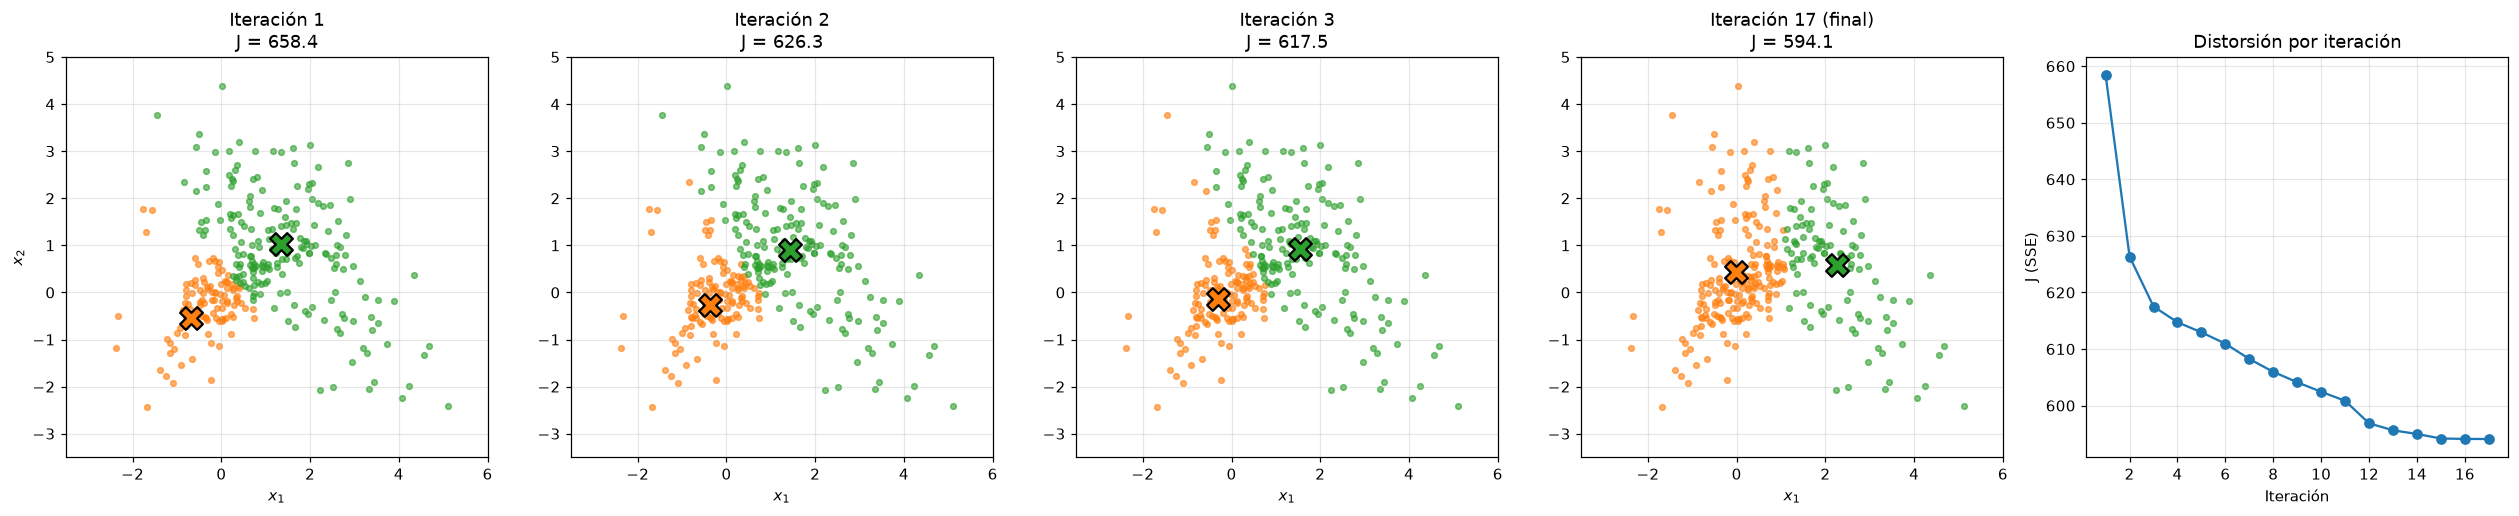

In [10]:
res = kmedias(X_tr, 2, np.random.default_rng(3), init="random")
print(f"Convergió en {res['n_iter']} iteraciones | SSE final = {res['sse']:.2f}")
print("SSE por iteración:", np.round([h[2] for h in res["historia"]], 2))

hist = res["historia"]
idx = sorted(set([0, 1, 2, len(hist) - 1]))
fig, axes = plt.subplots(1, len(idx) + 1, figsize=(4.6 * (len(idx) + 1), 4.8))
colores_cl = ["tab:orange", "tab:green", "tab:purple", "tab:brown"]
for ax, i in zip(axes, idx):
    C_i, lab_i, sse_i = hist[i]
    for k in range(2):
        ax.scatter(*X_tr[lab_i == k].T, s=14, alpha=0.6, color=colores_cl[k])
        ax.scatter(*C_i[k], marker="X", s=220, color=colores_cl[k], edgecolor="k", lw=1.5, zorder=5)
    ax.set_title(f"Iteración {i + 1}" + (" (final)" if i == len(hist) - 1 else "") + f"\nJ = {sse_i:.1f}")
    ax.set_xlim(XLIM); ax.set_ylim(YLIM); ax.set_xlabel("$x_1$")
axes[0].set_ylabel("$x_2$")
axes[-1].plot(np.arange(1, len(hist) + 1), [h[2] for h in hist], "o-")
axes[-1].set_xlabel("Iteración"); axes[-1].set_ylabel("J (SSE)"); axes[-1].set_title("Distorsión por iteración")
plt.tight_layout()
plt.show()

**Efecto de la inicialización y elección de $K$.** Se repite el algoritmo con 30 inicializaciones aleatorias para $K=2$ y $K=4$ y se observa la distribución del $J$ final. También se grafica $J$ en función de $K$ (curva del "codo").

K=2: SSE de 30 inicializaciones -> mín 594.04 | máx 663.50 | valores distintos (redondeados a 0.1): 4
      corridas que llegan al mejor mínimo (J <= 1.02 · mín): 21 de 30
K=4: SSE de 30 inicializaciones -> mín 268.20 | máx 289.36 | valores distintos (redondeados a 0.1): 11
      corridas que llegan al mejor mínimo (J <= 1.02 · mín): 19 de 30


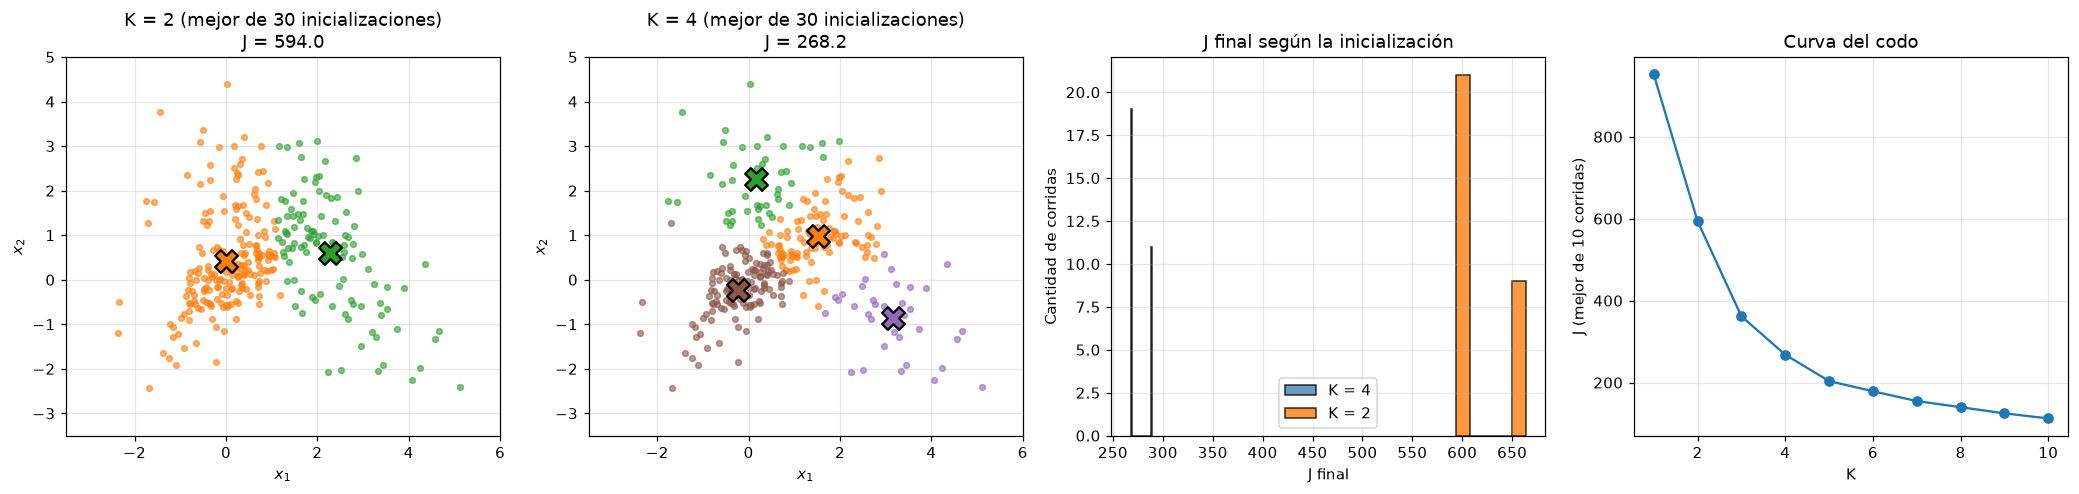

In [11]:
rng_k = np.random.default_rng(5)
mejores, sses = {}, {}
for K in (2, 4):
    mejores[K], sses[K] = kmedias_multiple(X_tr, K, rng_k, n_init=30)
    print(f"K={K}: SSE de 30 inicializaciones -> mín {sses[K].min():.2f} | máx {sses[K].max():.2f} | "
          f"valores distintos (redondeados a 0.1): {len(np.unique(sses[K].round(1)))}")
    print(f"      corridas que llegan al mejor mínimo (J <= 1.02 · mín): {np.sum(sses[K] <= 1.02 * sses[K].min())} de {len(sses[K])}")

Ks = np.arange(1, 11)
sse_vs_K = [kmedias_multiple(X_tr, K, rng_k, n_init=10)[0]["sse"] for K in Ks]

fig, axes = plt.subplots(1, 4, figsize=(19, 4.6))
for ax, K in zip(axes[:2], (2, 4)):
    r_ = mejores[K]
    for k in range(K):
        ax.scatter(*X_tr[r_["etiquetas"] == k].T, s=14, alpha=0.6, color=colores_cl[k % 4] if K <= 4 else None)
        ax.scatter(*r_["centros"][k], marker="X", s=220, color=colores_cl[k % 4], edgecolor="k", lw=1.5, zorder=5)
    ax.set_title(f"K = {K} (mejor de 30 inicializaciones)\nJ = {r_['sse']:.1f}")
    ax.set_xlim(XLIM); ax.set_ylim(YLIM); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
axes[2].hist(sses[4], bins=15, color="steelblue", edgecolor="k", alpha=0.8, label="K = 4")
axes[2].hist(sses[2], bins=5, color="tab:orange", edgecolor="k", alpha=0.8, label="K = 2")
axes[2].set_xlabel("J final"); axes[2].set_ylabel("Cantidad de corridas"); axes[2].legend()
axes[2].set_title("J final según la inicialización")
axes[3].plot(Ks, sse_vs_K, "o-")
axes[3].set_xlabel("K"); axes[3].set_ylabel("J (mejor de 10 corridas)"); axes[3].set_title("Curva del codo")
plt.tight_layout()
plt.show()

### 3.4 Uso como clasificador y comparación con las clases reales

Como $k$-medias no usa las etiquetas, se evalúa cuánto coinciden los grupos con las clases: se rotula cada grupo con la clase **mayoritaria** de sus miembros de entrenamiento, y para clasificar un punto nuevo se lo asigna al centroide más cercano y se le da el rótulo de ese grupo.

Centroides:
 [[ 2.2816  0.5891]
 [-0.0099  0.429 ]] 
Rótulo de cada grupo: [ 1 -1]
Acierto entrenamiento: 75.33% | prueba: 77.50%

Centros reales de las clases: [0. 0.] [1.5 1. ]
Medias muestrales de cada clase: [ 0.033 -0.007] [1.536 0.976]


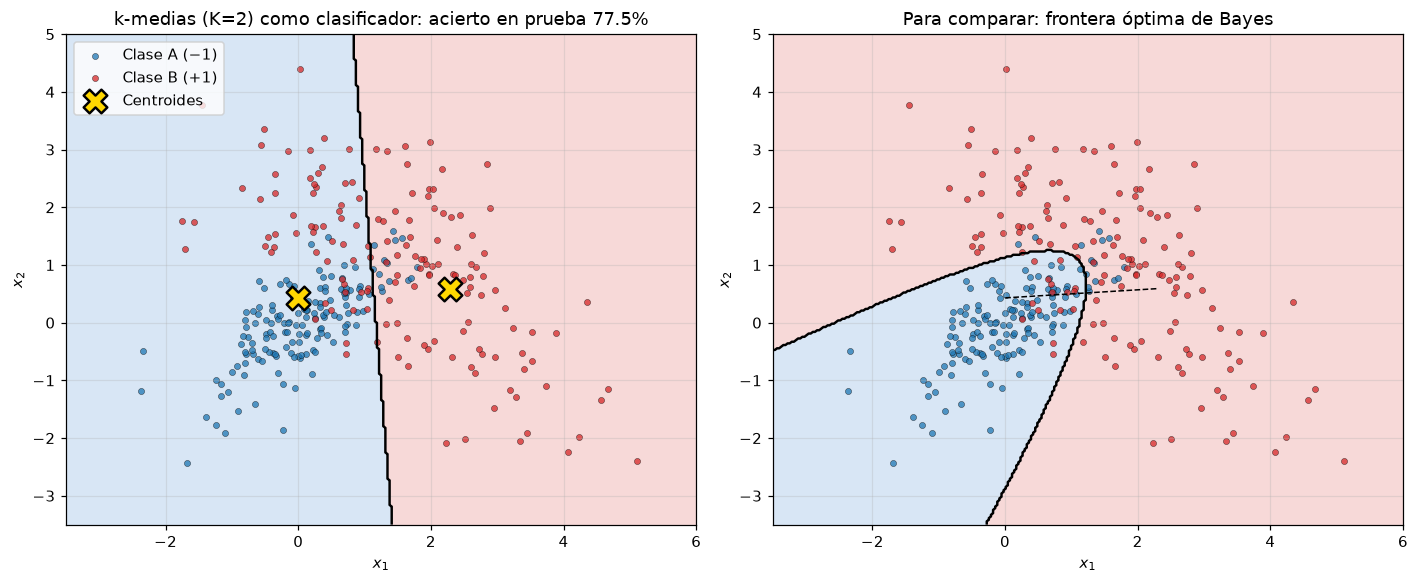

In [12]:
class KMediasClasificador:
    '''k-medias (no supervisado) + rotulado de cada grupo por voto mayoritario de las etiquetas de entrenamiento.'''

    def __init__(self, K=2, n_init=20, seed=0):
        self.K, self.n_init, self.seed = K, n_init, seed

    def fit(self, X, y):
        res, _ = kmedias_multiple(X, self.K, np.random.default_rng(self.seed), n_init=self.n_init)
        self.centros_ = res["centros"]
        self.rotulo_ = np.array([1 if np.sum(y[res["etiquetas"] == k]) >= 0 else -1 for k in range(self.K)])
        return self

    def predecir(self, X):
        d2 = ((X[:, None, :] - self.centros_[None]) ** 2).sum(-1)
        return self.rotulo_[d2.argmin(axis=1)]


km = KMediasClasificador(K=2).fit(X_tr, y_tr)
print("Centroides:\n", km.centros_, "\nRótulo de cada grupo:", km.rotulo_)
print(f"Acierto entrenamiento: {exactitud(y_tr, km.predecir(X_tr)) * 100:.2f}% | prueba: {exactitud(y_te, km.predecir(X_te)) * 100:.2f}%")
print("\nCentros reales de las clases:", MU[0], MU[1])
print("Medias muestrales de cada clase:", X_tr[y_tr == -1].mean(0).round(3), X_tr[y_tr == 1].mean(0).round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.4))
graficar_regiones(axes[0], km.predecir, XLIM, YLIM)
graficar_datos(axes[0], X_tr, y_tr, s=16)
for k in range(2):
    axes[0].scatter(*km.centros_[k], marker="X", s=240, color="gold", edgecolor="k", lw=1.6, zorder=6,
                    label="Centroides" if k == 0 else None)
axes[0].set_title(f"k-medias (K=2) como clasificador: acierto en prueba {exactitud(y_te, km.predecir(X_te)) * 100:.1f}%")
axes[0].legend(loc="upper left")

graficar_regiones(axes[1], bayes_predecir, XLIM, YLIM, borde=True)
graficar_datos(axes[1], X_tr, y_tr, s=16)
axes[1].plot(*np.array([km.centros_[0], km.centros_[1]]).T, "k--", lw=1)
axes[1].set_title("Para comparar: frontera óptima de Bayes")
for ax in axes:
    ax.set_xlim(XLIM); ax.set_ylim(YLIM); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
plt.tight_layout()
plt.show()

**Observaciones.**

- **Convergencia.** Desde la inicialización aleatoria elegida el algoritmo converge en 17 iteraciones, y la distorsión $J$ disminuye de forma **monótona** ($658\to594$), como se anticipó. Los centroides se acomodan y las asignaciones dejan de cambiar.
- **Mínimos locales.** Con 30 inicializaciones aleatorias y $K=2$ se obtienen 4 valores distintos de $J$ (entre $594$ y $664$): 21 de las 30 corridas llegan a la mejor solución, y las otras 9 quedan atrapadas en una peor ($J\approx660$). Con $K=4$ hay todavía más mínimos locales (11 valores distintos, entre $268$ y $289$; solo 19 de 30 corridas llegan al mejor). Por eso es necesario reiniciar varias veces y quedarse con la corrida de menor $J$.
- **Elección de $K$.** La curva $J(K)$ decae de manera suave, **sin un codo claro**: los datos no forman grupos bien separados (son dos nubes que se solapan), así que el criterio del codo no indica un $K$ evidente.
- **Los grupos no coinciden con las clases.** Con $K=2$ los centroides quedan en $(2.28,\,0.59)$ y $(-0.01,\,0.43)$, bastante lejos de las medias reales de las clases, $(1.5,\,1.0)$ y $(0,\,0)$. $k$-medias busca grupos compactos y de tamaño similar, y los reparte con una **frontera casi vertical** en $x_1\approx1.2$ (la bisectriz de los centroides). Pero las clases se distinguen por su *forma* (una compacta, la otra dispersa y rodeándola), que $k$-medias no ve.
- **Como clasificador** (rotulando los grupos con las etiquetas de entrenamiento) acierta $75.3\,\%$ en entrenamiento y $77.5\,\%$ en prueba ($78.7\pm2.5\,\%$ en las 30 réplicas): bastante mejor que el azar ($50\,\%$) para un método que **nunca vio las etiquetas**, pero peor que los supervisados.

---
## 4. Red de funciones de base radial (RBF)

> *Implemente el algoritmo de aprendizaje de las redes neuronales con funciones de base radial y pruébelo con los datos anteriores, grafique los resultados obtenidos.*

### 4.1 Marco teórico

Una **red RBF** tiene tres capas: la de entrada, una **capa oculta** de $M$ unidades con **funciones de base radial** (aquí gaussianas) y una **capa de salida lineal**:

$$
\varphi_j(\mathbf{x})=\exp\!\left(-\frac{\|\mathbf{x}-\mathbf{c}_j\|^2}{2\sigma^2}\right),\qquad
f(\mathbf{x})=\sum_{j=1}^{M}w_j\,\varphi_j(\mathbf{x})+w_0,\qquad
\hat y=\mathrm{sgn}\,f(\mathbf{x}).
$$

Cada unidad oculta responde solo cerca de su **centro** $\mathbf{c}_j$ (respuesta **local**, de ancho $\sigma$), a diferencia de las unidades sigmoideas de un perceptrón multicapa, que responden en semiespacios. La red transforma los datos a un espacio de $M$ dimensiones donde, según el **teorema de Cover**, es más probable que las clases sean linealmente separables, y ahí actúa un clasificador lineal (la capa de salida). Con suficientes unidades es un aproximador universal de funciones.

**Aprendizaje híbrido en dos etapas.** Se aprovecha que los parámetros de las dos capas juegan papeles distintos:

1. **Capa oculta (no supervisada).** Los **centros** $\mathbf{c}_j$ se obtienen con **$k$-medias** (sección 3) sobre los datos de entrada, de modo que las unidades se ubican donde hay datos. El **ancho** se fija con la heurística $\sigma=d_{\max}/\sqrt{2M}$, con $d_{\max}$ la mayor distancia entre centros, para que las gaussianas cubran el espacio sin solaparse en exceso ni quedar demasiado aisladas.
2. **Capa de salida (supervisada).** Con los parámetros anteriores fijos, la salida es **lineal en los pesos**. Sea $\boldsymbol{\Phi}\in\mathbb{R}^{N\times(M+1)}$ la matriz de activaciones (con una columna de unos para el sesgo) y $\mathbf{t}\in\{\pm1\}^N$ los objetivos. Minimizar el error cuadrático $\|\mathbf{t}-\boldsymbol{\Phi}\mathbf{w}\|^2+\lambda\|\mathbf{w}\|^2$ es un problema **convexo con solución cerrada**:
$$
\mathbf{w}=(\boldsymbol{\Phi}^\top\boldsymbol{\Phi}+\lambda\mathbf{I})^{-1}\boldsymbol{\Phi}^\top\mathbf{t}.
$$
(Equivalentemente, se puede resolver iterativamente con la regla delta/LMS.) El término $\lambda$ (regularización) estabiliza el cálculo.

**Complejidad del modelo.** El número de unidades $M$ es el hiperparámetro principal: con pocas unidades la red **subajusta** (frontera demasiado simple) y con muchas **sobreajusta** (memoriza el ruido del entrenamiento). Se lo elige con **validación cruzada** sobre el conjunto de entrenamiento.

### 4.2 Implementación

In [13]:
class RBF:
    '''Red de funciones de base radial gaussianas con entrenamiento híbrido (k-medias + mínimos cuadrados).'''

    def __init__(self, M=8, ridge=1e-3, escala_sigma=1.0, n_init=5, seed=0):
        self.M, self.ridge, self.escala_sigma, self.n_init, self.seed = M, ridge, escala_sigma, n_init, seed

    def _phi(self, X):
        d2 = ((X[:, None, :] - self.C_[None, :, :]) ** 2).sum(-1)
        return np.c_[np.exp(-d2 / (2 * self.sigma_ ** 2)), np.ones(len(X))]      # activaciones + sesgo

    def fit(self, X, y):
        # Etapa 1 (no supervisada): centros por k-medias, ancho por heurística d_max / sqrt(2M)
        res, _ = kmedias_multiple(X, self.M, np.random.default_rng(self.seed), n_init=self.n_init, init="kmeans++")
        self.C_ = res["centros"]
        dist_centros = np.linalg.norm(self.C_[:, None] - self.C_[None], axis=-1)
        self.sigma_ = max(self.escala_sigma * dist_centros.max() / np.sqrt(2 * self.M), 1e-3)
        # Etapa 2 (supervisada): pesos de salida por mínimos cuadrados regularizados (solución cerrada)
        Phi = self._phi(X)
        self.w_ = np.linalg.solve(Phi.T @ Phi + self.ridge * np.eye(Phi.shape[1]), Phi.T @ y)
        return self

    def decision(self, X):
        return self._phi(X) @ self.w_

    def predecir(self, X):
        return np.where(self.decision(X) >= 0, 1, -1)


def validacion_cruzada(crear_modelo, X, y, folds=5, seed=0):
    '''Acierto medio de validación cruzada estratificada de `folds` pliegues.'''
    r = np.random.default_rng(seed)
    pliegue = np.empty(len(y), dtype=int)
    for c in (-1, 1):
        idx = r.permutation(np.where(y == c)[0])
        pliegue[idx] = np.arange(len(idx)) % folds
    accs = []
    for f in range(folds):
        m = crear_modelo().fit(X[pliegue != f], y[pliegue != f])
        accs.append(exactitud(y[pliegue == f], m.predecir(X[pliegue == f])))
    return np.mean(accs)

### 4.3 Aplicación: efecto del número de unidades $M$

Se entrena la red para distintos $M$. Se informa el acierto en entrenamiento, el de **validación cruzada** (5 pliegues, calculado solo con el entrenamiento; es el que se usa para elegir $M$) y, solo con fines ilustrativos, el de prueba.

In [14]:
Ms = [2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64]
acc_rbf = {"train": [], "cv": [], "test": []}
for M in Ms:
    m = RBF(M=M).fit(X_tr, y_tr)
    acc_rbf["train"].append(exactitud(y_tr, m.predecir(X_tr)))
    acc_rbf["cv"].append(validacion_cruzada(lambda M=M: RBF(M=M), X_tr, y_tr))
    acc_rbf["test"].append(exactitud(y_te, m.predecir(X_te)))

M_opt = Ms[int(np.argmax(acc_rbf["cv"]))]
print(f"{'M':>3} | {'σ':>6} | {'entrenam.':>9} | {'valid. cruzada':>14} | {'prueba':>7}")
for i, M in enumerate(Ms):
    print(f"{M:>3} | {RBF(M=M).fit(X_tr, y_tr).sigma_:6.3f} | {acc_rbf['train'][i] * 100:8.2f}% | {acc_rbf['cv'][i] * 100:13.2f}% | {acc_rbf['test'][i] * 100:6.2f}%")
print(f"\nM elegido por validación cruzada: {M_opt}")

rbf = RBF(M=M_opt).fit(X_tr, y_tr)
print(f"RBF (M={M_opt}) -> acierto entrenamiento: {exactitud(y_tr, rbf.predecir(X_tr)) * 100:.2f}% | prueba: {exactitud(y_te, rbf.predecir(X_te)) * 100:.2f}%")

  M |      σ | entrenam. | valid. cruzada |  prueba
  2 |  1.149 |    81.00% |         81.00% |  80.57%
  3 |  1.275 |    86.00% |         86.00% |  86.58%
  4 |  1.559 |    88.67% |         88.67% |  87.71%
  6 |  1.285 |    89.67% |         88.67% |  88.06%
  8 |  1.398 |    90.00% |         90.00% |  88.47%
 12 |  1.276 |    90.33% |         89.67% |  88.79%
 16 |  1.357 |    91.00% |         90.33% |  88.66%
 24 |  1.108 |    91.33% |         90.67% |  88.52%


 32 |  1.127 |    91.00% |         90.67% |  88.41%
 48 |  0.920 |    91.33% |         90.00% |  88.59%


 64 |  0.797 |    90.67% |         90.00% |  88.35%

M elegido por validación cruzada: 24
RBF (M=24) -> acierto entrenamiento: 91.33% | prueba: 88.52%


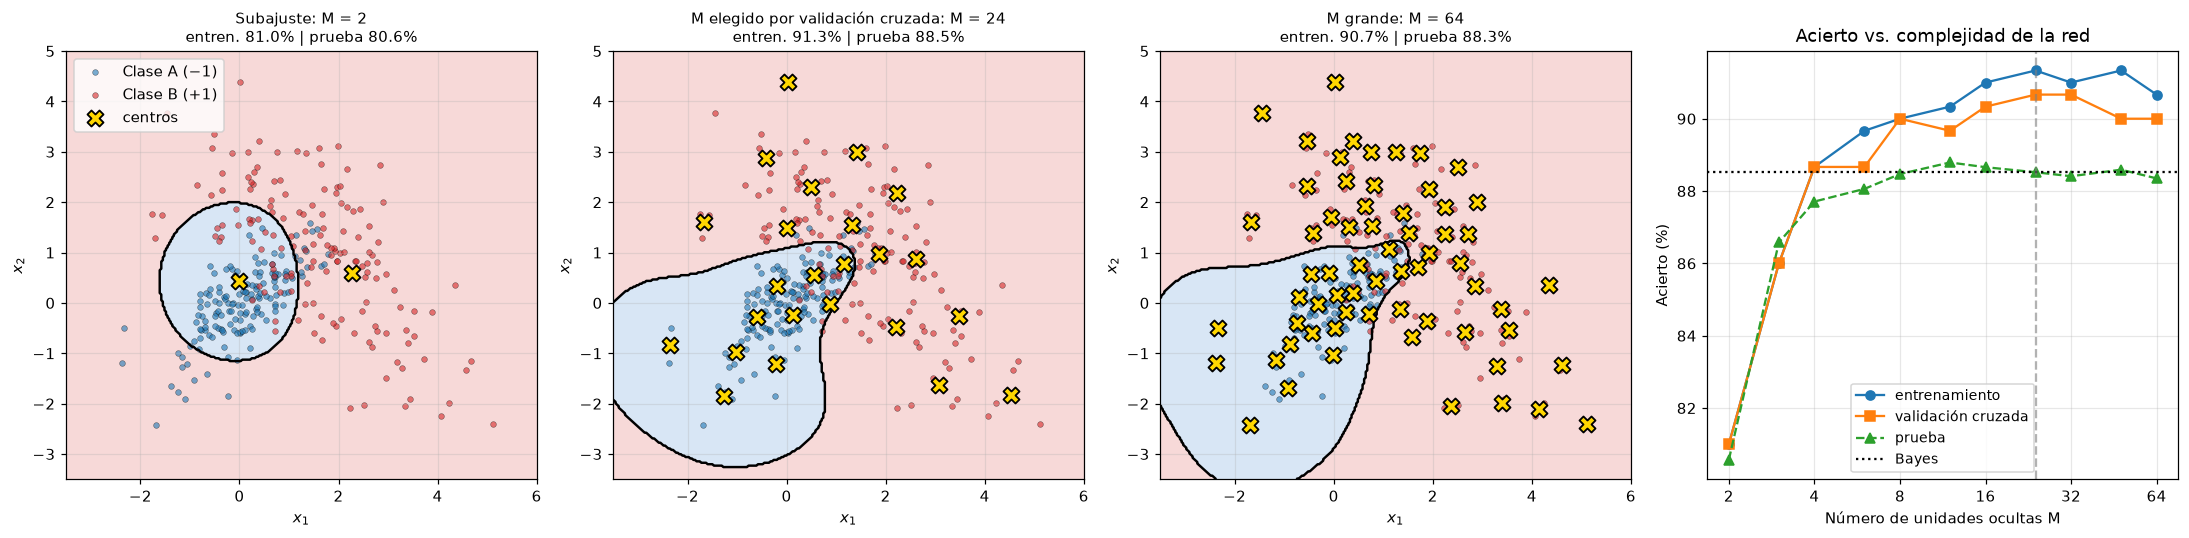

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, M, titulo in [(axes[0], Ms[0], "Subajuste"), (axes[1], M_opt, "M elegido por validación cruzada"), (axes[2], Ms[-1], "M grande")]:
    m = RBF(M=M).fit(X_tr, y_tr)
    graficar_regiones(ax, m.predecir, XLIM, YLIM)
    graficar_datos(ax, X_tr, y_tr, s=14, alpha=0.6)
    ax.scatter(*m.C_.T, marker="X", s=110, color="gold", edgecolor="k", lw=1.2, zorder=6, label="centros")
    ax.set_xlim(XLIM); ax.set_ylim(YLIM); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(f"{titulo}: M = {M}\nentren. {exactitud(y_tr, m.predecir(X_tr)) * 100:.1f}% | prueba {exactitud(y_te, m.predecir(X_te)) * 100:.1f}%", fontsize=10)
axes[0].legend(loc="upper left")

ax = axes[3]
ax.plot(Ms, np.array(acc_rbf["train"]) * 100, "o-", label="entrenamiento")
ax.plot(Ms, np.array(acc_rbf["cv"]) * 100, "s-", label="validación cruzada")
ax.plot(Ms, np.array(acc_rbf["test"]) * 100, "^--", label="prueba")
ax.axhline(acc_bayes_mc * 100, color="k", ls=":", label="Bayes")
ax.axvline(M_opt, color="gray", ls="--", alpha=0.6)
ax.set_xscale("log"); ax.set_xticks([2, 4, 8, 16, 32, 64]); ax.set_xticklabels([2, 4, 8, 16, 32, 64]); ax.minorticks_off()
ax.set_xlabel("Número de unidades ocultas M"); ax.set_ylabel("Acierto (%)")
ax.set_title("Acierto vs. complejidad de la red"); ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

Para ver qué hace la capa oculta, se muestran las activaciones de las unidades (una "mancha" local alrededor de cada centro) y la **función de salida** $f(\mathbf{x})$ de la red elegida, cuya curva de nivel $f=0$ es la frontera de decisión.

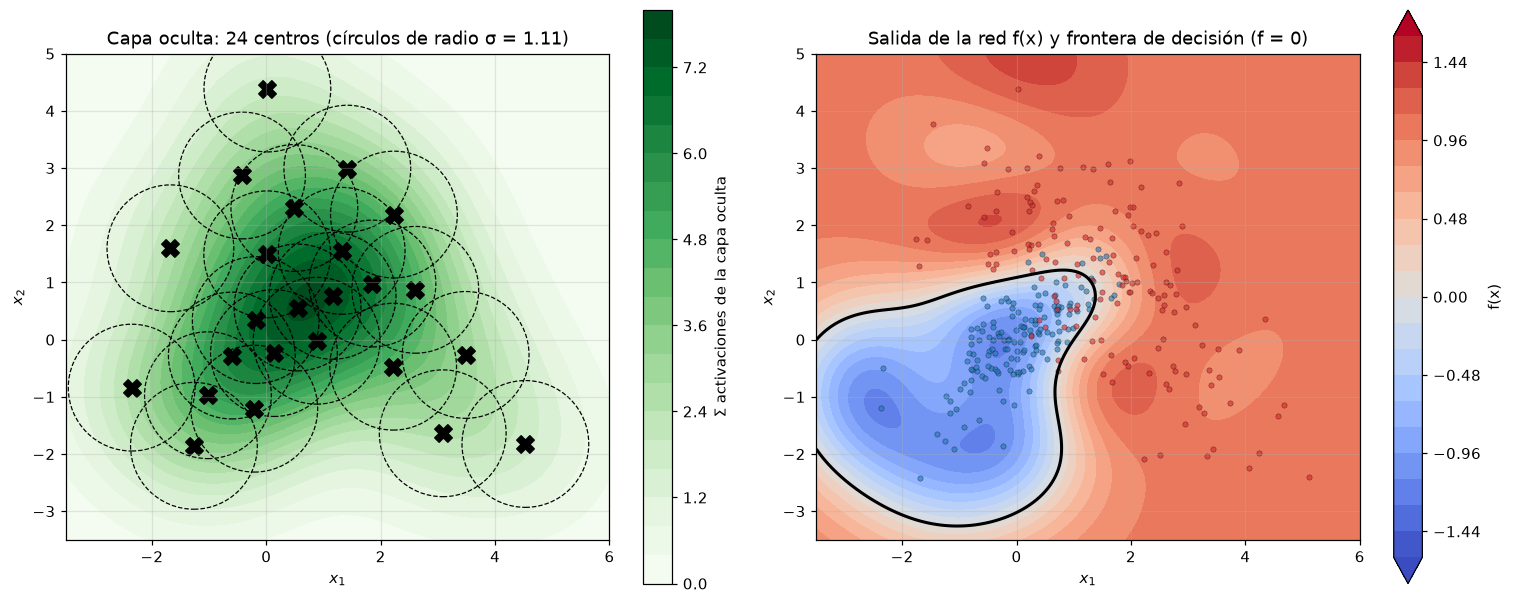

In [16]:
xx, yy = np.meshgrid(np.linspace(*XLIM, 250), np.linspace(*YLIM, 250))
grilla = np.c_[xx.ravel(), yy.ravel()]
F = rbf.decision(grilla).reshape(xx.shape)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6))
# Activación total de la capa oculta (suma de las gaussianas) y los centros
act = rbf._phi(grilla)[:, :-1].sum(axis=1).reshape(xx.shape)
im0 = axes[0].contourf(xx, yy, act, levels=20, cmap="Greens")
fig.colorbar(im0, ax=axes[0], label="Σ activaciones de la capa oculta")
axes[0].scatter(*rbf.C_.T, marker="X", s=130, color="k")
for c in rbf.C_:
    axes[0].add_patch(plt.Circle(c, rbf.sigma_, fill=False, color="k", lw=0.8, ls="--"))
axes[0].set_title(f"Capa oculta: {rbf.M} centros (círculos de radio σ = {rbf.sigma_:.2f})")

# Salida de la red
im1 = axes[1].contourf(xx, yy, F, levels=np.linspace(-1.6, 1.6, 21), cmap="coolwarm", extend="both")
fig.colorbar(im1, ax=axes[1], label="f(x)")
axes[1].contour(xx, yy, F, levels=[0], colors="k", linewidths=2)
graficar_datos(axes[1], X_tr, y_tr, s=12, alpha=0.6)
axes[1].set_title("Salida de la red f(x) y frontera de decisión (f = 0)")
for ax in axes:
    ax.set_xlim(XLIM); ax.set_ylim(YLIM); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal")
plt.tight_layout()
plt.show()

**Observaciones.**

- **Subajuste con pocas unidades.** Con $M=2$ la región de la clase A es un óvalo simple y el acierto es de solo $81\,\%$ (entrenamiento) y $80.6\,\%$ (prueba). Con $M=3$ y $M=4$ la frontera ya se curva y el acierto en prueba sube a $86.6\,\%$ y $87.7\,\%$.
- **Meseta a partir de $M\approx8$.** El acierto de prueba se estabiliza en $\approx88.4$ a $88.8\,\%$ para cualquier $M\ge8$, ya muy cerca del óptimo de Bayes ($88.9\,\%$ en este conjunto). El acierto de entrenamiento sigue creciendo un poco más ($\approx91\,\%$), y queda **unos 3 puntos por encima** del de prueba: un sobreajuste leve. Es suave porque la heurística del ancho tiende a reducir $\sigma$ al aumentar $M$ ($1.56$ con $M=4$, $0.80$ con $M=64$), y porque los pesos de salida se regularizan.
- **Elección de $M$.** La validación cruzada elige $M=24$ ($90.7\,\%$ de acierto de validación). Pero la curva de validación cruzada es ruidosa: con 300 datos su error típico es de $\approx1.7$ puntos, por lo que $M=8$, $16$, $24$ y $32$ son estadísticamente indistinguibles. En las 30 réplicas el $M$ elegido varió entre 4 y 32, sin consecuencias importantes para el acierto en prueba.
- **Frontera.** Con $M=24$ la red dibuja una región curva alrededor de la clase A, parecida a la de Bayes, y acierta $88.5\,\%$ en prueba (Bayes: $88.9\,\%$). Es una **mejora de unos 5 puntos** respecto del mejor clasificador lineal.
- **Papel de la capa oculta.** Los centros que encuentra $k$-medias se ubican donde hay datos (más densos en la zona de solapamiento), y cada unidad responde solo en un entorno de su centro. La salida de la red $f(\mathbf{x})$ es una combinación suave de esas "manchas", y su curva de nivel $f=0$ es la frontera.

---
## 5. k vecinos más cercanos

> *Implemente el algoritmo de los $k$-vecinos más cercanos y pruébelo con los datos anteriores, grafique los resultados obtenidos.*

### 5.1 Marco teórico

$k$-NN es un clasificador **no paramétrico** y **basado en memoria**: no ajusta ningún modelo, solo **guarda** el conjunto de entrenamiento. Para clasificar un punto nuevo $\mathbf{x}$:

1. se calculan las distancias (euclídeas) a todos los puntos de entrenamiento;
2. se toman los $k$ más cercanos;
3. se asigna la clase **mayoritaria** entre esos $k$ vecinos.

(Con dos clases conviene $k$ **impar** para evitar empates.) Es una estimación local de la probabilidad a posteriori, $\hat P(\omega_i|\mathbf{x})=k_i/k$, seguida de la regla de Bayes.

**Propiedades.**

- **Consistencia:** el resultado de Cover y Hart muestra que, con $N\to\infty$, el error de 1-NN es a lo sumo el doble del error de Bayes, $P^*\le P_{1NN}\le2P^*(1-P^*)$, y que si $k\to\infty$ con $k/N\to0$ el error tiende al de Bayes.
- **$k$ controla el compromiso sesgo-varianza.** Con $k$ **pequeño** la frontera es muy irregular y sigue el ruido de los datos (baja sesgo, alta varianza: *sobreajuste*; con $k=1$ el acierto en entrenamiento es 100 % de manera trivial, porque cada punto es su propio vecino). Con $k$ **grande** la frontera es suave, pero puede ignorar estructura real (*subajuste*; en el extremo $k=N$ se predice siempre la clase mayoritaria).
- **Selección de $k$.** Se elige por validación; aquí se usa **leave-one-out** sobre el entrenamiento (cada punto se clasifica usando a los demás), que se calcula barato para $k$-NN.
- **Costo:** no hay etapa de entrenamiento, pero la predicción cuesta $O(N d)$ por cada punto y hay que guardar todos los datos. Además es sensible a la escala de las variables y pierde eficacia en dimensiones altas (maldición de la dimensionalidad).

### 5.2 Implementación

Para evaluar muchos valores de $k$ a la vez, se ordenan los vecinos de cada punto una sola vez; el voto con $k$ vecinos es el signo de la suma acumulada de las primeras $k$ etiquetas ($\pm1$).

In [17]:
class KNN:
    '''k vecinos más cercanos (distancia euclídea, voto mayoritario). Etiquetas en {-1, +1}; k impar.'''

    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X_, self.y_ = X, y
        return self

    def _etiquetas_ordenadas(self, X, excluir_propio=False):
        '''Etiquetas de los puntos de entrenamiento ordenados por distancia creciente a cada fila de X.'''
        d2 = ((X[:, None, :] - self.X_[None, :, :]) ** 2).sum(-1)
        if excluir_propio:
            np.fill_diagonal(d2, np.inf)               # leave-one-out: un punto no es su propio vecino (X debe ser el entrenamiento)
        return self.y_[np.argsort(d2, axis=1, kind="stable")]

    def predecir_varios_k(self, X, ks, excluir_propio=False):
        acum = np.cumsum(self._etiquetas_ordenadas(X, excluir_propio), axis=1)      # suma de las primeras j etiquetas
        return {k: np.where(acum[:, k - 1] >= 0, 1, -1) for k in ks}

    def predecir(self, X):
        return self.predecir_varios_k(X, [self.k])[self.k]

### 5.3 Aplicación: efecto de $k$

Se calcula el acierto en función de $k$ (impar, de 1 a 61): sobre el entrenamiento (*resustitución*, sobreoptimista), por **leave-one-out** (para elegir $k$) y sobre el conjunto de prueba (solo ilustrativo).

In [18]:
ks = np.arange(1, 62, 2)
knn = KNN().fit(X_tr, y_tr)

pred_tr = knn.predecir_varios_k(X_tr, ks)                          # incluye a cada punto como su propio vecino
pred_loo = knn.predecir_varios_k(X_tr, ks, excluir_propio=True)    # leave-one-out
pred_te = knn.predecir_varios_k(X_te, ks)

acc_knn = {"train": np.array([exactitud(y_tr, pred_tr[k]) for k in ks]),
           "loo": np.array([exactitud(y_tr, pred_loo[k]) for k in ks]),
           "test": np.array([exactitud(y_te, pred_te[k]) for k in ks])}
k_opt = int(ks[np.argmax(acc_knn["loo"])])
print(f"k elegido por leave-one-out: {k_opt}  (acierto LOO = {acc_knn['loo'].max() * 100:.2f}%)")
print(f"{'k':>3} | {'entrenam.':>9} | {'leave-one-out':>13} | {'prueba':>7}")
for k in [1, 3, 5, 9, 15, k_opt, 31, 61]:
    i = list(ks).index(k)
    print(f"{k:>3} | {acc_knn['train'][i] * 100:8.2f}% | {acc_knn['loo'][i] * 100:12.2f}% | {acc_knn['test'][i] * 100:6.2f}%" + ("  <- elegido" if k == k_opt else ""))

k elegido por leave-one-out: 17  (acierto LOO = 89.67%)
  k | entrenam. | leave-one-out |  prueba
  1 |   100.00% |        85.00% |  86.23%
  3 |    93.67% |        86.00% |  86.65%
  5 |    91.00% |        87.67% |  87.87%
  9 |    90.67% |        89.00% |  87.82%
 15 |    91.00% |        89.00% |  87.88%
 17 |    90.00% |        89.67% |  88.14%  <- elegido
 31 |    90.00% |        88.33% |  87.70%
 61 |    87.33% |        87.33% |  86.79%


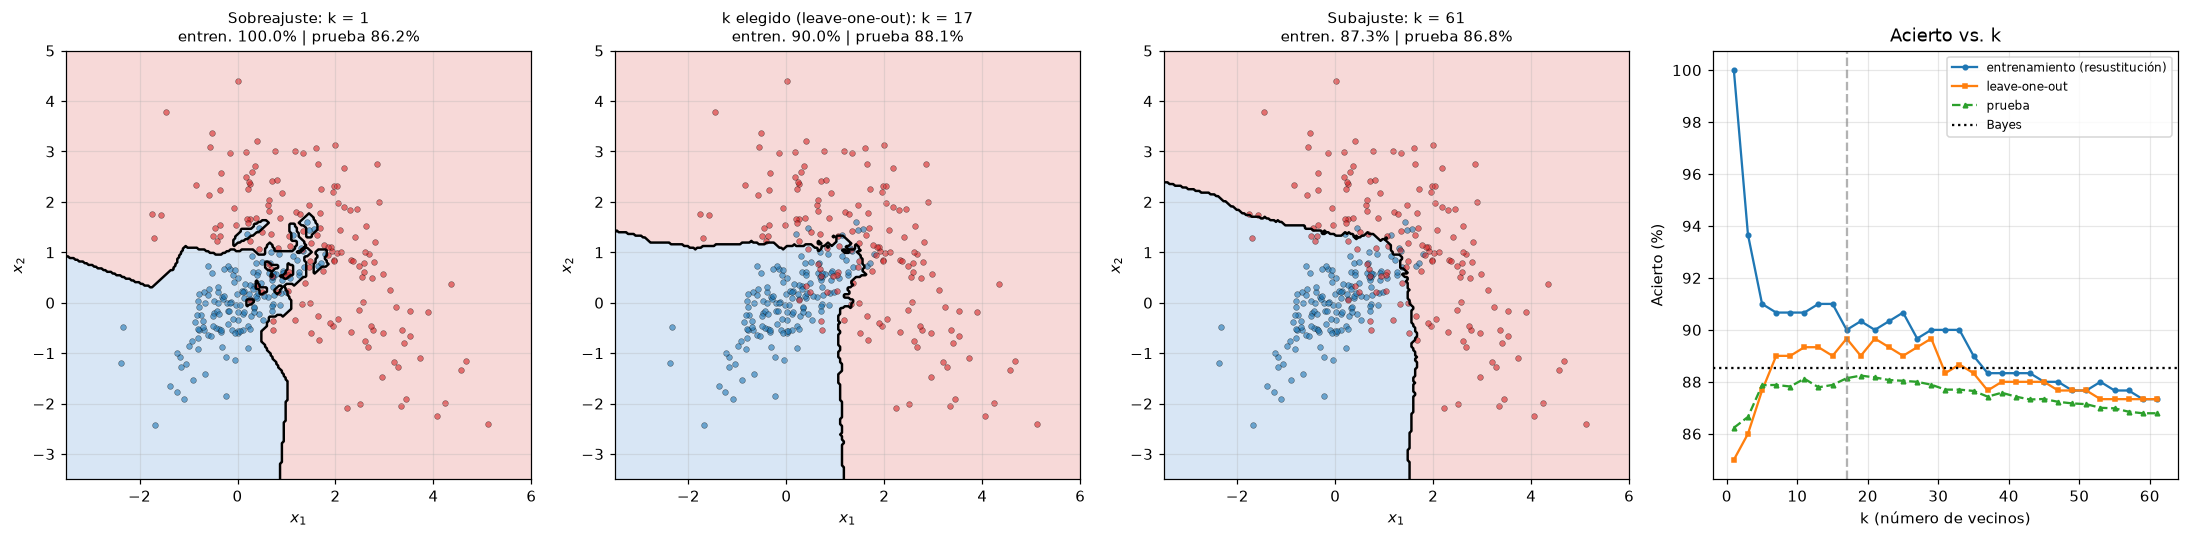

In [19]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, k, titulo in [(axes[0], 1, "Sobreajuste"), (axes[1], k_opt, "k elegido (leave-one-out)"), (axes[2], 61, "Subajuste")]:
    m = KNN(k).fit(X_tr, y_tr)
    graficar_regiones(ax, m.predecir, XLIM, YLIM, n=250)
    graficar_datos(ax, X_tr, y_tr, s=14, alpha=0.6)
    ax.set_xlim(XLIM); ax.set_ylim(YLIM); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(f"{titulo}: k = {k}\nentren. {exactitud(y_tr, pred_tr[k]) * 100:.1f}% | prueba {exactitud(y_te, m.predecir(X_te)) * 100:.1f}%", fontsize=10)

ax = axes[3]
ax.plot(ks, acc_knn["train"] * 100, "o-", ms=3, label="entrenamiento (resustitución)")
ax.plot(ks, acc_knn["loo"] * 100, "s-", ms=3, label="leave-one-out")
ax.plot(ks, acc_knn["test"] * 100, "^--", ms=3, label="prueba")
ax.axhline(acc_bayes_mc * 100, color="k", ls=":", label="Bayes")
ax.axvline(k_opt, color="gray", ls="--", alpha=0.6)
ax.set_xlabel("k (número de vecinos)"); ax.set_ylabel("Acierto (%)")
ax.set_title("Acierto vs. k"); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Observaciones.**

- **$k=1$ (sobreajuste).** El acierto en entrenamiento es del $100\,\%$ de manera trivial (cada punto es su propio vecino), pero por leave-one-out baja a $85.0\,\%$ y en prueba a $86.2\,\%$. La frontera es muy irregular, con "islas" que siguen puntos aislados, es decir, el ruido de la muestra.
- **$k$ grande (subajuste).** Con $k=61$ la frontera es suave pero demasiado simple ($86.8\,\%$ en prueba): cada decisión promedia una región tan grande que se pierde la forma de la frontera.
- **$k$ intermedio.** El acierto de prueba es casi constante, $\approx87.7$ a $88.2\,\%$, para $k$ entre 5 y 35. Leave-one-out elige $k=17$ ($88.1\,\%$ en prueba, a $0.7$ puntos del óptimo). La curva de leave-one-out es ruidosa, así que el $k$ exacto es poco crítico (en las réplicas el $k$ elegido tuvo mediana 16 y rango 3 a 51).
- **Estimaciones optimistas.** El acierto de resustitución (entrenamiento) es engañoso: decrece con $k$ desde 100 %. El de leave-one-out del $k$ elegido ($89.7\,\%$) también es algo optimista (≈1.5 puntos sobre el de prueba), porque se lo selecciona como el máximo de muchas estimaciones ruidosas.
- **Forma de la frontera.** Es más irregular que la de Bayes o la de la RBF (que tienden a ser suaves): $k$-NN no impone ninguna forma, solo sigue la distribución local de los puntos. Esto le da flexibilidad, pero con pocos datos (300) la frontera es ruidosa.

---
## 6. Comparación de los métodos

> *Compare y comente los resultados obtenidos por los distintos métodos.*

### 6.1 Resultados sobre el mismo conjunto de datos

Se resumen los desempeños de todos los métodos, con los hiperparámetros elegidos solo con los datos de entrenamiento ($M$ de la RBF y $k$ de $k$-NN), y se dibujan las regiones de decisión.

In [20]:
knn_opt = KNN(k_opt).fit(X_tr, y_tr)
metodos = {
    "Perceptrón (pesos finales)": perc,
    "Perceptrón con bolsillo": perc_pk,
    "k-medias (K=2) + rotulado": km,
    f"Red RBF (M={M_opt})": rbf,
    f"k-NN (k={k_opt})": knn_opt,
    "Bayes (conoce la fdp real)": type("Bayes", (), {"predecir": staticmethod(bayes_predecir)})(),
}

print(f"{'Método':<30} | {'entrenamiento':>13} | {'prueba':>7} | tipo")
tipos = ["supervisado, lineal", "supervisado, lineal", "no supervisado, lineal", "supervisado, no lineal (paramétrico)",
         "supervisado, no lineal (no paramétrico)", "referencia óptima"]
for (nombre, m), tipo in zip(metodos.items(), tipos):
    print(f"{nombre:<30} | {exactitud(y_tr, m.predecir(X_tr)) * 100:12.2f}% | {exactitud(y_te, m.predecir(X_te)) * 100:6.2f}% | {tipo}")
print(f"{'Mejor clasificador lineal (MC)':<30} | {'-':>13} | {acc_lineal_mc * 100:6.2f}% | referencia lineal")

Método                         | entrenamiento |  prueba | tipo
Perceptrón (pesos finales)     |        73.67% |  70.73% | supervisado, lineal
Perceptrón con bolsillo        |        85.00% |  83.56% | supervisado, lineal
k-medias (K=2) + rotulado      |        75.33% |  77.50% | no supervisado, lineal
Red RBF (M=24)                 |        91.33% |  88.52% | supervisado, no lineal (paramétrico)


k-NN (k=17)                    |        90.00% |  88.14% | supervisado, no lineal (no paramétrico)
Bayes (conoce la fdp real)     |        90.00% |  88.86% | referencia óptima
Mejor clasificador lineal (MC) |             - |  82.94% | referencia lineal


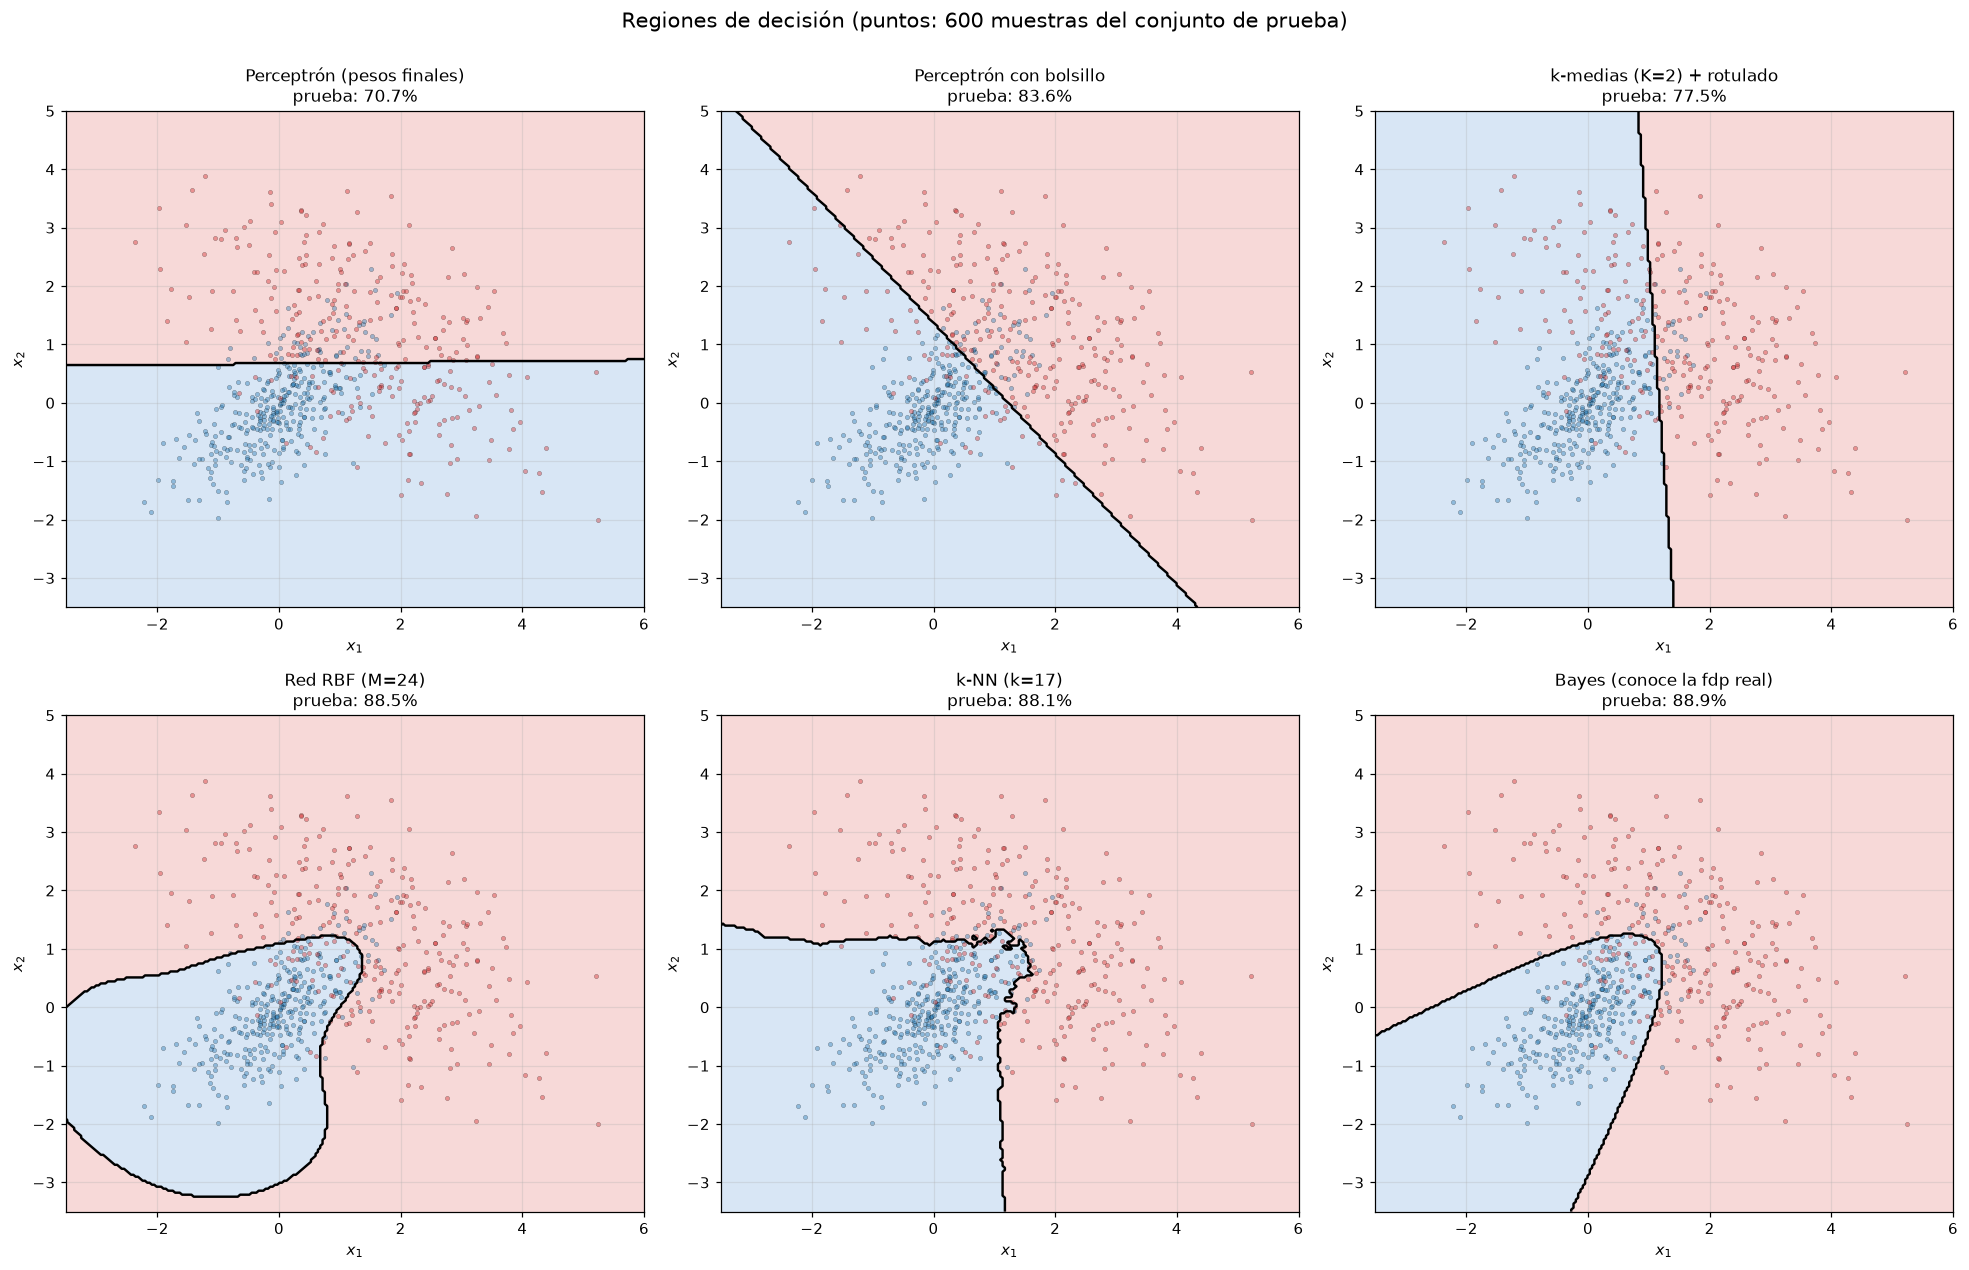

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11.5))
for ax, (nombre, m) in zip(axes.ravel(), metodos.items()):
    graficar_regiones(ax, m.predecir, XLIM, YLIM, n=250)
    graficar_datos(ax, X_te[:600], y_te[:600], s=8, alpha=0.4)
    ax.set_xlim(XLIM); ax.set_ylim(YLIM); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
    ax.set_title(f"{nombre}\nprueba: {exactitud(y_te, m.predecir(X_te)) * 100:.1f}%", fontsize=11)
fig.suptitle("Regiones de decisión (puntos: 600 muestras del conjunto de prueba)", y=1.0, fontsize=14)
plt.tight_layout()
plt.show()

### 6.2 Repetición del experimento con 30 conjuntos de datos distintos

Una única realización puede engañar: el resultado de un método depende de la muestra concreta de entrenamiento. Se repite entonces **todo el procedimiento** (generación de datos, ajuste y selección de hiperparámetros solo con el entrenamiento, y evaluación en un conjunto de prueba de 1000 muestras por clase) con 30 semillas distintas, y se informa la media y la dispersión del acierto en prueba.

In [22]:
def una_replica(seed):
    r = np.random.default_rng(1000 + seed)
    Xa, ya = generar_datos(150, r)
    Xb, yb = generar_datos(1000, r)
    sal = {}
    sal["Perceptrón (pesos finales)"] = exactitud(yb, Perceptron(epocas=200, seed=seed).fit(Xa, ya).predecir(Xb))
    sal["Perceptrón con bolsillo"] = exactitud(yb, Perceptron(epocas=200, pocket=True, seed=seed).fit(Xa, ya).predecir(Xb))
    sal["k-medias (K=2) + rotulado"] = exactitud(yb, KMediasClasificador(K=2, n_init=10, seed=seed).fit(Xa, ya).predecir(Xb))
    # RBF: M por validación cruzada solo con el entrenamiento
    cv = [validacion_cruzada(lambda M=M: RBF(M=M, n_init=3, seed=seed), Xa, ya, seed=seed) for M in (2, 4, 8, 16, 32)]
    M_ = (2, 4, 8, 16, 32)[int(np.argmax(cv))]
    sal["Red RBF (M por validación cruzada)"] = exactitud(yb, RBF(M=M_, n_init=3, seed=seed).fit(Xa, ya).predecir(Xb))
    sal["_M"] = M_
    # k-NN: k por leave-one-out solo con el entrenamiento
    kn = KNN().fit(Xa, ya)
    loo = kn.predecir_varios_k(Xa, ks, excluir_propio=True)
    k_ = int(ks[np.argmax([exactitud(ya, loo[k]) for k in ks])])
    sal["k-NN (k por leave-one-out)"] = exactitud(yb, KNN(k_).fit(Xa, ya).predecir(Xb))
    sal["_k"] = k_
    sal["Bayes (conoce la fdp real)"] = exactitud(yb, bayes_predecir(Xb))
    return sal


R = 30
replicas = [una_replica(s) for s in range(R)]
nombres_met = [n for n in replicas[0] if not n.startswith("_")]
accs = {n: np.array([r_[n] for r_ in replicas]) * 100 for n in nombres_met}

print(f"{'Método':<36} | {'media':>6} | {'desvío':>6} | {'mín':>5} | {'máx':>5}")
for n in nombres_met:
    a = accs[n]
    print(f"{n:<36} | {a.mean():5.2f}% | {a.std():5.2f}  | {a.min():4.1f}% | {a.max():4.1f}%")
print(f"{'Mejor clasificador lineal (MC)':<36} | {acc_lineal_mc * 100:5.2f}%")
# Comparaciones pareadas (mismos datos en cada réplica): diferencia media, error estándar y réplicas ganadas
def comparar(n1, n2):
    d = accs[n1] - accs[n2]
    print(f"{n1} − {n2}: {d.mean():+.2f} ± {d.std(ddof=1) / np.sqrt(R):.2f} (error estándar) | gana en {np.sum(d > 0)} de {R} réplicas")


print()
comparar("Red RBF (M por validación cruzada)", "k-NN (k por leave-one-out)")
comparar("Bayes (conoce la fdp real)", "Red RBF (M por validación cruzada)")
comparar("Bayes (conoce la fdp real)", "k-NN (k por leave-one-out)")
comparar("Perceptrón con bolsillo", "Perceptrón (pesos finales)")
comparar("k-medias (K=2) + rotulado", "Perceptrón (pesos finales)")
print("\nM elegido por validación cruzada en las 30 réplicas:", {int(m): int(c) for m, c in zip(*np.unique([r_['_M'] for r_ in replicas], return_counts=True))})
print("k elegido por leave-one-out (mediana, rango):", int(np.median([r_['_k'] for r_ in replicas])),
      (min(r_['_k'] for r_ in replicas), max(r_['_k'] for r_ in replicas)))

Método                               |  media | desvío |   mín |   máx
Perceptrón (pesos finales)           | 76.80% |  5.16  | 55.3% | 83.0%
Perceptrón con bolsillo              | 82.24% |  0.92  | 80.3% | 84.2%
k-medias (K=2) + rotulado            | 78.68% |  2.47  | 74.2% | 83.4%
Red RBF (M por validación cruzada)   | 87.88% |  0.72  | 86.2% | 89.3%
k-NN (k por leave-one-out)           | 87.28% |  0.86  | 85.4% | 88.4%
Bayes (conoce la fdp real)           | 88.62% |  0.63  | 87.2% | 89.7%
Mejor clasificador lineal (MC)       | 82.94%

Red RBF (M por validación cruzada) − k-NN (k por leave-one-out): +0.60 ± 0.14 (error estándar) | gana en 22 de 30 réplicas
Bayes (conoce la fdp real) − Red RBF (M por validación cruzada): +0.74 ± 0.11 (error estándar) | gana en 28 de 30 réplicas
Bayes (conoce la fdp real) − k-NN (k por leave-one-out): +1.35 ± 0.15 (error estándar) | gana en 30 de 30 réplicas
Perceptrón con bolsillo − Perceptrón (pesos finales): +5.44 ± 0.94 (error estándar) | gana en 2

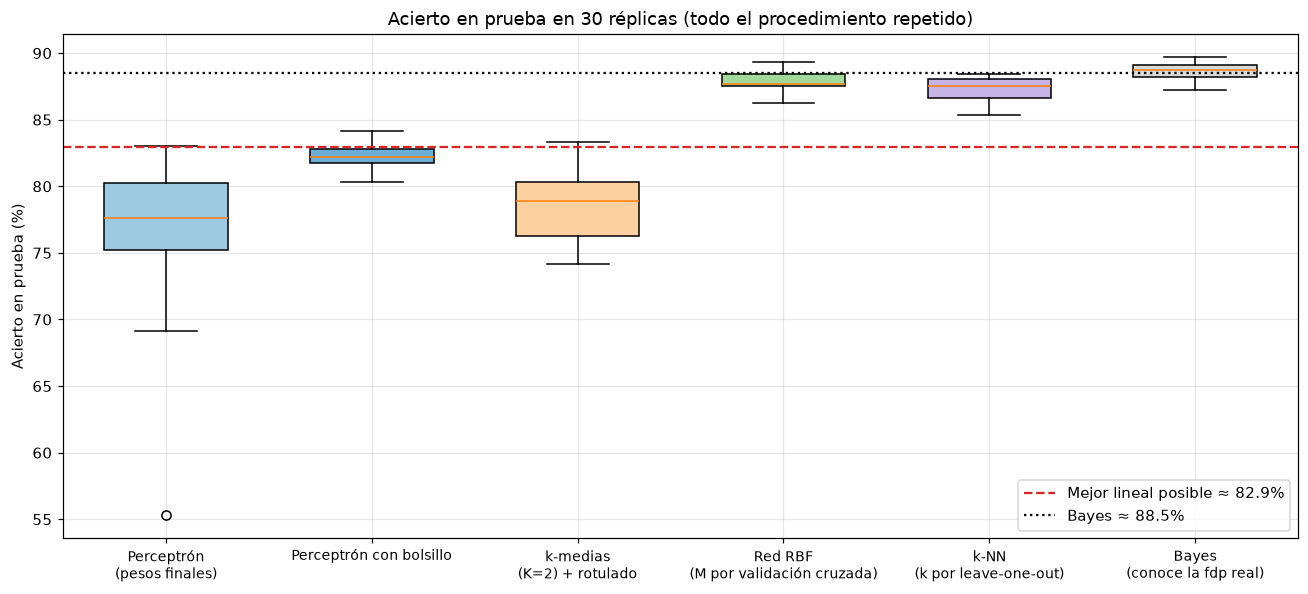

In [23]:
fig, ax = plt.subplots(figsize=(12, 5.5))
datos = [accs[n] for n in nombres_met]
bp = ax.boxplot(datos, orientation="vertical", patch_artist=True, widths=0.6)
for patch, c in zip(bp["boxes"], ["#9ecae1", "#6baed6", "#fdd0a2", "#a1d99b", "#c7b3e6", "#d9d9d9"]):
    patch.set_facecolor(c)
ax.axhline(acc_lineal_mc * 100, color="tab:red", ls="--", label=f"Mejor lineal posible ≈ {acc_lineal_mc * 100:.1f}%")
ax.axhline(acc_bayes_mc * 100, color="k", ls=":", label=f"Bayes ≈ {acc_bayes_mc * 100:.1f}%")
ax.set_xticks(range(1, len(nombres_met) + 1))
ax.set_xticklabels([n.replace(" (", "\n(") for n in nombres_met], fontsize=9)
ax.set_ylabel("Acierto en prueba (%)")
ax.set_title(f"Acierto en prueba en {R} réplicas (todo el procedimiento repetido)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

#### Resumen cuantitativo

| Método | Prueba (esta muestra) | Prueba, 30 réplicas (media ± desvío) | Frontera |
|:--|:--:|:--:|:--|
| Perceptrón (pesos finales) | $70.7\,\%$ | $76.8\pm5.2\,\%$ | recta (inestable) |
| Perceptrón con bolsillo | $83.6\,\%$ | $82.2\pm0.9\,\%$ | recta |
| $k$-medias ($K=2$) + rotulado | $77.5\,\%$ | $78.7\pm2.5\,\%$ | recta (no usa etiquetas) |
| Red RBF | $88.5\,\%$ | $87.9\pm0.7\,\%$ | curva suave |
| $k$-NN | $88.1\,\%$ | $87.3\pm0.9\,\%$ | curva irregular |
| **Bayes** (referencia) | $88.9\,\%$ | $88.6\pm0.6\,\%$ | cuádrica |

Comparaciones **pareadas** (mismos datos en cada réplica): RBF $-$ $k$-NN $=+0.60\pm0.14$ puntos (RBF mejor en 22 de 30 réplicas); Bayes $-$ RBF $=+0.74\pm0.11$ y Bayes $-$ $k$-NN $=+1.35\pm0.15$ (Bayes mejor en 28 y 30 de 30); bolsillo $-$ perceptrón básico $=+5.4\pm0.9$; $k$-medias $-$ perceptrón básico $=+1.9\pm1.1$ (diferencia no concluyente: gana en 18 de 30).

#### Comentarios

1. **La linealidad es el factor decisivo.** Los métodos con frontera recta (perceptrón y $k$-medias con $K=2$) están acotados por el mejor clasificador lineal ($\approx82.9\,\%$), mientras que RBF y $k$-NN, con frontera curva, llegan al $87$ a $88\,\%$, a menos de 1.5 puntos del óptimo. La causa es que, con covarianzas distintas, la frontera óptima de las clases no es una recta.
2. **El perceptrón es inestable en problemas no separables.** No converge, y sus pesos finales dependen del azar de la última época (desvío de $5.2$ puntos, con corridas de $55\,\%$). El bolsillo lo estabiliza ($0.9$ puntos de desvío) y alcanza el mejor desempeño lineal, aunque eso siga siendo insuficiente aquí.
3. **$k$-medias es no supervisado.** No usa las etiquetas, así que sus grupos reflejan la *geometría* de los datos (partición en regiones compactas) y no las clases. Rotulado a posteriori es mejor que el azar pero inferior a los supervisados, y depende de la inicialización. Su verdadero valor aquí es como etapa previa de la RBF (centros), donde aporta una buena cobertura del espacio.
4. **RBF y $k$-NN son comparables, con una ligera ventaja de la RBF.** La RBF es mejor en promedio ($+0.6\pm0.14$ puntos), una diferencia pequeña, aunque consistente, y esperable porque su base gaussiana y su frontera suave encajan con datos gaussianos. Difieren en lo práctico:

| | Red RBF | $k$-NN |
|:--|:--|:--|
| Tipo | paramétrico (centros y pesos) | no paramétrico (guarda todos los datos) |
| Entrenamiento | $k$-medias + mínimos cuadrados | ninguno |
| Costo por predicción | $O(Md)$ | $O(Nd)$ |
| Memoria | $M$ centros y pesos | los $N$ datos |
| Hiperparámetros | $M$, ancho, regularización | $k$ (y la métrica) |
| Frontera | suave | irregular, depende de la muestra |

5. **Ninguno alcanza el óptimo.** Quedan $0.7$ puntos (RBF) y $1.4$ puntos ($k$-NN) por debajo de Bayes, de forma sistemática. La razón es que con solo 300 muestras de entrenamiento los métodos *estiman* la frontera, y ese error de estimación (varianza) no existe para Bayes, que conoce las distribuciones.
6. **Hiperparámetros.** Todos requieren decisiones: épocas y variante (perceptrón), $K$ e inicialización ($k$-medias), $M$ y ancho (RBF), $k$ (k-NN). Los aquí elegidos con validación cruzada o leave-one-out son ruidosos (con 300 datos, $\pm1.7$ puntos), aunque el resultado final resultó poco sensible dentro de un rango amplio ($M\ge8$, $5\le k\le35$).
7. **Una sola muestra puede engañar.** La dispersión entre réplicas (sobre todo en el perceptrón, con rangos de más de 25 puntos) muestra que las conclusiones deben apoyarse en repeticiones y no en un único conjunto de datos.

---
## 7. Conclusiones

1. **Problema.** Dos clases gaussianas correlacionadas con distinta covarianza producen una frontera óptima curva. El error de Bayes es de $11.5\,\%$, y el mejor clasificador lineal posible llega a $17.1\,\%$ de error.
2. **Perceptrón.** Converge solo si las clases son separables (se verificó en un caso de referencia). Con solapamiento sus pesos oscilan y el resultado es muy variable; el algoritmo de bolsillo lo estabiliza y alcanza el límite lineal ($\approx83\,\%$), que no basta para este problema.
3. **$k$-medias.** Converge siempre (la distorsión baja de manera monótona), pero a mínimos locales: hay que reiniciar. Es no supervisado, por lo que sus grupos no coinciden con las clases y como clasificador rinde $\approx78\,\%$. Sirve sobre todo para ubicar los centros de la red RBF.
4. **Red RBF.** Con entrenamiento híbrido ($k$-medias para la capa oculta y mínimos cuadrados para la salida) logra una frontera curva y $87.9\pm0.7\,\%$, a menos de un punto del óptimo, y es poco sensible a $M$ a partir de $\approx8$ unidades.
5. **$k$-NN.** Sin entrenamiento y con un solo hiperparámetro ($k$) alcanza $87.3\pm0.9\,\%$. Con $k$ pequeño sobreajusta y con $k$ grande subajusta; la frontera es más irregular y la predicción más costosa que con la RBF.
6. **Comparación.** Lo que más importa es si el método puede representar una frontera no lineal: los dos que pueden (RBF y $k$-NN) superan en unos 5 puntos a los lineales. Entre ellos las diferencias son pequeñas, y los dos quedan algo por debajo de Bayes por tener solo 300 muestras. Las conclusiones se sostuvieron al repetir el experimento con 30 conjuntos de datos distintos.